# COMP6008 Group 12 — Consolidated Smart Irrigation RL Notebook

**Review copy compiled from existing group notebooks.** Contributors: Raina Shah (DDPG), Arnav Dangmali (TD3), Malaika Noor (SAC). This notebook retains the original training functions, shared daily water-balance environment and agent implementations. The **original five notebooks, checkpoint files, result CSVs and test partitions are not edited**.

**Execution policy:** Running all cells loads the experiment definition and saved outputs; it **does not retrain** models. The DDPG/TD3 training runners are present with their execution flags deliberately off. SAC's separate experiment/analysis cells are preserved under an opt-in guard. The recorded held-out test results (2021–2024) and the optional 2017 validation replay are distinct.

To execute, work from the cloned repository's `notebooks/` directory, with `../data/Irrigation_Data_Audit.zip` and `../outputs/` available. Dependencies: Python, Gymnasium, PyTorch, NumPy, pandas, Matplotlib, IPython, Jupyter and FFmpeg for optional MP4 export. Example: `pip install "gymnasium>=1.0,<2" "torch>=2" "numpy>=1.22" "pandas>=2" "matplotlib>=3.7" ipykernel nbconvert`.


In [1]:

!git clone --depth 1 https://github.com/rainashah/comp6008-smart-irrigation-rl.git /content/comp6008-smart-irrigation-rl

%cd /content/comp6008-smart-irrigation-rl/notebooks

%pip install -q "gymnasium>=1.0,<2" "numpy>=1.22" "pandas>=2" "matplotlib>=3.7" "torch>=2"


Cloning into '/content/comp6008-smart-irrigation-rl'...
remote: Enumerating objects: 172, done.
remote: Counting objects: 100% (172/172), done.
remote: Compressing objects: 100% (160/160), done.
remote: Total 172 (delta 9), reused 160 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (172/172), 120.37 MiB | 16.12 MiB/s, done.
Resolving deltas: 100% (9/9), done.
Updating files: 100% (150/150), done.
/content/comp6008-smart-irrigation-rl/notebooks


## A. Shared experiment definition and simulator
The maize simulation uses 18 observation values, a normalised action in [-1, 1] mapping to 0–20 mm/day irrigation, and a 150-day season. Training planting years: 2005–2016; validation: 2017–2020; final test: 2021–2024. Five final seeds per agent and 100,000 steps each. See `docs/FIXED_EXPERIMENT_SETTINGS.md` for the frozen protocol.


In [2]:
from __future__ import annotations

import hashlib
import json
import platform
import random
import time
import warnings
from collections import deque
from dataclasses import asdict, dataclass, replace
from datetime import date, timedelta
from itertools import product
from pathlib import Path
from typing import Any
from zipfile import ZipFile

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env

RUNTIME = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "gymnasium": gym.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "torch": torch.__version__,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}
RUNTIME


{'python': '3.13.16',
 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
 'gymnasium': '1.4.0',
 'numpy': '2.1.3',
 'pandas': '2.2.3',
 'torch': '2.11.0+cpu',
 'device': 'cpu'}

In [3]:
# Ensure relative data paths remain compatible with the source notebooks.
import os
from pathlib import Path
if (Path.cwd()/'notebooks/01_ddpg.ipynb').exists():
    os.chdir(Path.cwd()/'notebooks')
print('Working directory:', Path.cwd())


Working directory: /content/comp6008-smart-irrigation-rl/notebooks


In [4]:
DATA_CANDIDATES = [
    Path("../data/Irrigation_Data_Audit.zip"),  # when launched from notebooks/
    Path("data/Irrigation_Data_Audit.zip"),    # when working directory is repository root
    Path("Irrigation_Data_Audit.zip"),
    Path("/content/Irrigation_Data_Audit.zip"),
    Path("../irrigation_audit/kyabram_080091_daily.json"),
    Path("irrigation_audit/kyabram_080091_daily.json"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Upload Irrigation_Data_Audit.zip and rerun this cell. "
        "The expected Colab path is /content/Irrigation_Data_Audit.zip."
    )

DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Using:", DATA_PATH.resolve())
print("SHA-256:", DATA_SHA256)

# Resolve outputs consistently from repository root, notebooks/, or standalone Colab.
PROJECT_ROOT = next((p.resolve() for p in (Path.cwd(), Path.cwd().parent)
                     if (p / "notebooks").is_dir()), Path.cwd())
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
AGENT_OUTPUT_DIRS = {name: OUTPUT_ROOT / name for name in ("ddpg", "td3", "sac")}

def agent_output_dir(agent_name):
    if agent_name not in AGENT_OUTPUT_DIRS:
        raise ValueError("Choose ddpg, td3, or sac")
    directory = AGENT_OUTPUT_DIRS[agent_name]
    directory.mkdir(parents=True, exist_ok=True)
    return directory


Using: /content/comp6008-smart-irrigation-rl/data/Irrigation_Data_Audit.zip
SHA-256: ce6d02d87ea7cb980f61f78bdd288d6ad035744042dae1eb3e43f0facaa54e08


In [5]:
TRAIN_YEARS = tuple(range(2005, 2017))
VALIDATION_YEARS = tuple(range(2017, 2021))
TEST_YEARS = tuple(range(2021, 2025))
SEASON_SPLITS = {
    "train": TRAIN_YEARS,
    "validation": VALIDATION_YEARS,
    "test": TEST_YEARS,
    "all": TRAIN_YEARS + VALIDATION_YEARS + TEST_YEARS,
}


@dataclass(frozen=True)
class EnvironmentConfig:
    capacity_mm: float = 111.33333333333334
    initial_storage_fraction: float = 0.80
    max_irrigation_mm: float = 20.0
    irrigation_efficiency: float = 0.85
    season_length_days: int = 150
    planting_month: int = 11
    planting_day: int = 1
    planting_day_offset: int = 0
    kc_multiplier: float = 1.0
    irrigation_weight: float = 1.0
    shortage_weight: float = 10.0
    drainage_weight: float = 1.0
    rainfall_scale_mm: float = 20.0
    eto_scale_mm: float = 10.0
    history_days: int = 7

    def __post_init__(self):
        if self.capacity_mm <= 0 or self.max_irrigation_mm <= 0:
            raise ValueError("Storage capacity and irrigation limit must be positive")
        if not 0 < self.initial_storage_fraction <= 1:
            raise ValueError("Initial storage fraction must be in (0, 1]")
        if not 0 < self.irrigation_efficiency <= 1:
            raise ValueError("Irrigation efficiency must be in (0, 1]")
        if self.season_length_days != 150 or self.history_days != 7:
            raise ValueError("The fixed experiment uses 150 days and seven history days")
        if not 0 < self.kc_multiplier <= 1.1:
            raise ValueError("Kc multiplier must be in (0, 1.1]")
        if min(self.irrigation_weight, self.shortage_weight, self.drainage_weight) < 0:
            raise ValueError("Reward weights must be non-negative")


ENV_CONFIG = EnvironmentConfig()

SHARED_TRAINING = {
    "gamma": 0.995,
    "tau": 0.005,
    "replay_capacity": 100_000,
    "batch_size": 128,
    "random_exploration_steps": 1_500,
    "hidden_sizes": (128, 128),
    "optimiser": "Adam",
    "optimiser_betas": (0.9, 0.999),
    "optimiser_epsilon": 1e-8,
    "updates_per_environment_step": 1,
    "final_training_steps": 100_000,
    "tuning_steps": 30_000,
    "evaluation_interval": 5_000,
    "final_checkpoint": 100_000,
    "final_seeds": (11, 22, 33, 44, 55),
    "tuning_seeds": (101, 202),
}

AGENT_TUNING_GRIDS = {
    "ddpg": [
        {"learning_rate": lr, "exploration_std": std}
        for lr, std in product((1e-4, 3e-4), (0.1, 0.2))
    ],
    "td3": [
        {"learning_rate": lr, "exploration_std": std}
        for lr, std in product((1e-4, 3e-4), (0.1, 0.2))
    ],
    "sac": [
        {"learning_rate": lr, "alpha": alpha}
        for lr, alpha in product((1e-4, 3e-4), (0.1, 0.2))
    ],
}

AGENT_SETTINGS = {
    "ddpg": {"owner": "Raina Shah", "selected_learning_rate": None, "selected_exploration_std": None},
    "td3": {
        "owner": "Arnav Dangmali", "selected_learning_rate": None, "selected_exploration_std": None,
        "policy_delay": 2, "target_smoothing_std": 0.2, "target_noise_clip": 0.5,
    },
    "sac": {
        "owner": "Malaika Noor", "selected_learning_rate": None, "selected_alpha": None,
        "formulation": "Haarnoja et al. (2018), separate value network, fixed alpha",
        "log_std_bounds": None,  # document before SAC training
    },
}

ROBUSTNESS_CONFIGS = {
    "capacity_0.8": replace(ENV_CONFIG, capacity_mm=0.8 * ENV_CONFIG.capacity_mm),
    "capacity_1.2": replace(ENV_CONFIG, capacity_mm=1.2 * ENV_CONFIG.capacity_mm),
    "root_zone_0.6m": replace(ENV_CONFIG, capacity_mm=72.0),
    "efficiency_0.75": replace(ENV_CONFIG, irrigation_efficiency=0.75),
    "efficiency_0.95": replace(ENV_CONFIG, irrigation_efficiency=0.95),
    "planting_minus_14d": replace(ENV_CONFIG, planting_day_offset=-14),
    "planting_plus_14d": replace(ENV_CONFIG, planting_day_offset=14),
    "kc_0.9": replace(ENV_CONFIG, kc_multiplier=0.9),
    "kc_1.1": replace(ENV_CONFIG, kc_multiplier=1.1),
}

REWARD_SENSITIVITY_CONFIGS = {
    "shortage_weight_5": replace(ENV_CONFIG, shortage_weight=5.0),
    "shortage_weight_20": replace(ENV_CONFIG, shortage_weight=20.0),
}


def make_season_schedule(seed, total_steps):
    # Shared episode schedule; independent from network and exploration RNGs.
    episode_count = int(np.ceil(total_steps / ENV_CONFIG.season_length_days)) + 1
    rng = np.random.default_rng(seed)
    return tuple(int(year) for year in rng.choice(TRAIN_YEARS, size=episode_count, replace=True))


def configuration_fingerprint(config=ENV_CONFIG):
    payload = {"environment": asdict(config), "training": SHARED_TRAINING, "data_sha256": DATA_SHA256}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


EXPERIMENT_TOTALS = {
    "tuning": 3 * 4 * 2 * 30_000,
    "five_seed_final_training": 3 * 5 * 100_000,
    "reward_sensitivity": 3 * 2 * 2 * 30_000,
}
EXPERIMENT_TOTALS["total_learning_interactions"] = sum(EXPERIMENT_TOTALS.values())

print("Configuration fingerprint:", configuration_fingerprint())
print("Planned learning interactions:", EXPERIMENT_TOTALS)


Configuration fingerprint: 7fc3978e1036c4192871625454e78e071d739b3e01762ebbe99108120866f282
Planned learning interactions: {'tuning': 720000, 'five_seed_final_training': 1500000, 'reward_sensitivity': 360000, 'total_learning_interactions': 2580000}


In [6]:
KYABRAM_MEMBER = 'irrigation_audit/kyabram_080091_daily.json'

class KyabramIrrigationEnv(gym.Env):
    metadata = {'render_modes': ['rgb_array'], 'render_fps': 8}

    def __init__(self, climate_path=DATA_PATH, split='train', config=ENV_CONFIG, render_mode=None):
        super().__init__()
        if render_mode not in (None, "rgb_array"):
            raise ValueError("Supported render_mode: rgb_array or None")
        self.render_mode = render_mode
        if split not in SEASON_SPLITS:
            raise ValueError(f'Unknown split: {split}')
        self.config = config
        self.split = split
        self.allowed_years = SEASON_SPLITS[split]
        records = self._load_records(Path(climate_path))
        self._weather, self._dates = self._build_seasons(records)
        self.action_space = spaces.Box(-1.0, 1.0, shape=(1,), dtype=np.float32)
        self.observation_space = spaces.Box(
            low=np.zeros(18, dtype=np.float32),
            high=np.array([1.0, 1.0, 1.1, 1.0] + [np.inf] * 14, dtype=np.float32),
            dtype=np.float32,
        )
        self.season_year = None
        self.day = config.season_length_days
        self.storage_mm = 0.0
        self.previous_irrigation_mm = 0.0
        self._terminated = True

    @staticmethod
    def _load_records(path):
        if path.is_dir():
            path = path / 'kyabram_080091_daily.json'
        if path.suffix.lower() == '.zip':
            with ZipFile(path) as archive:
                payload = json.loads(archive.read(KYABRAM_MEMBER))
        else:
            payload = json.loads(path.read_text())
        records = {}
        for index, row in enumerate(payload):
            try:
                current_date = date.fromisoformat(row['date'])
                rain = float(row['rain_mm'])
                eto = float(row['eto_mm'])
            except (KeyError, TypeError, ValueError) as exc:
                raise ValueError(f'Malformed climate row {index}') from exc
            if current_date in records or not np.isfinite([rain, eto]).all():
                raise ValueError(f'Invalid climate input on {current_date}')
            if rain < 0 or eto < 0:
                raise ValueError(f'Negative climate input on {current_date}')
            records[current_date] = (rain, eto)
        return records

    def _build_seasons(self, records):
        weather, dates = {}, {}
        block_length = self.config.history_days + self.config.season_length_days
        for year in SEASON_SPLITS['all']:
            planting = date(year, self.config.planting_month, self.config.planting_day)
            planting += timedelta(days=self.config.planting_day_offset)
            start = planting - timedelta(days=self.config.history_days)
            block_dates = tuple(start + timedelta(days=i) for i in range(block_length))
            missing = [day for day in block_dates if day not in records]
            if missing:
                raise ValueError(f'Season {year} is missing {missing[0]}')
            weather[year] = np.asarray([records[day] for day in block_dates], dtype=np.float64)
            dates[year] = block_dates
        return weather, dates

    def _kc(self, day):
        if day >= self.config.season_length_days:
            return 0.0
        if day < 30:
            base = 0.30
        elif day < 70:
            base = 0.30 + 0.90 * (day - 29) / 40
        elif day < 120:
            base = 1.20
        else:
            base = 1.20 - 0.85 * (day - 119) / 30
        return self.config.kc_multiplier * base

    def _observation(self):
        history = self._weather[self.season_year][self.day:self.day + 7][::-1]
        observation = np.concatenate([
            np.array([
                self.storage_mm / self.config.capacity_mm,
                self.day / self.config.season_length_days,
                self._kc(self.day) / 1.2,
                self.previous_irrigation_mm / self.config.max_irrigation_mm,
            ]),
            history[:, 0] / self.config.rainfall_scale_mm,
            history[:, 1] / self.config.eto_scale_mm,
        ]).astype(np.float32)
        if not np.isfinite(observation).all() or not self.observation_space.contains(observation):
            raise RuntimeError('Invalid observation produced')
        return observation

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        options = {} if options is None else dict(options)
        unknown_options = set(options) - {'season_year'}
        if unknown_options:
            raise ValueError(f'Unknown reset options: {sorted(unknown_options)}')
        requested_year = options.get('season_year')
        if requested_year is None:
            self.season_year = self.allowed_years[int(self.np_random.integers(len(self.allowed_years)))]
        elif int(requested_year) in self.allowed_years:
            self.season_year = int(requested_year)
        else:
            raise ValueError(f'Season {requested_year} is not in the {self.split} split')
        self.day = 0
        self.storage_mm = self.config.initial_storage_fraction * self.config.capacity_mm
        self.previous_irrigation_mm = 0.0
        self._terminated = False
        decision_date = self._dates[self.season_year][7]
        info = {'split': self.split, 'season_year': self.season_year, 'decision_date': decision_date.isoformat()}
        self._visual_info = info.copy()
        self._visual_reward = 0.0
        self._visual_total_irrigation = 0.0
        return self._observation(), info

    def step(self, action):
        if self._terminated:
            raise RuntimeError('Episode ended; call reset()')
        action = np.asarray(action, dtype=np.float32).reshape(-1)
        if action.shape != (1,) or not self.action_space.contains(action):
            raise ValueError('Expected one finite action in [-1, 1]')

        irrigation = 0.5 * self.config.max_irrigation_mm * (float(action[0]) + 1.0)
        weather_index = 7 + self.day
        rain, eto = self._weather[self.season_year][weather_index]
        decision_date = self._dates[self.season_year][weather_index]
        kc = self._kc(self.day)
        potential_et = kc * float(eto)
        depletion = float(np.clip(0.55 + 0.04 * (5.0 - potential_et), 0.1, 0.8))
        minimum = (1.0 - depletion) * self.config.capacity_mm

        storage_before = self.storage_mm
        incoming = storage_before + float(rain) + self.config.irrigation_efficiency * irrigation
        drainage = max(0.0, incoming - self.config.capacity_mm)
        wet_storage = incoming - drainage
        stress_coefficient = min(1.0, wet_storage / minimum)
        actual_et = min(wet_storage, stress_coefficient * potential_et)
        storage_after = wet_storage - actual_et
        shortage = max(0.0, minimum - storage_after)

        irrigation_penalty = self.config.irrigation_weight * irrigation / self.config.max_irrigation_mm
        shortage_penalty = self.config.shortage_weight * shortage / minimum
        drainage_penalty = self.config.drainage_weight * drainage / self.config.max_irrigation_mm
        reward = -(irrigation_penalty + shortage_penalty + drainage_penalty)
        self.storage_mm = storage_after
        self.previous_irrigation_mm = irrigation
        self.day += 1
        self._terminated = self.day == self.config.season_length_days
        residual = storage_after - (storage_before + rain + self.config.irrigation_efficiency * irrigation - drainage - actual_et)
        info = {
            'season_year': self.season_year, 'completed_day': self.day,
            'decision_date': decision_date.isoformat(), 'irrigation_mm': irrigation,
            'rain_mm': float(rain), 'eto_mm': float(eto), 'kc': kc,
            'potential_et_mm': potential_et, 'actual_et_mm': actual_et,
            'depletion_fraction': depletion, 'stress_coefficient': stress_coefficient,
            'minimum_storage_mm': minimum, 'storage_before_mm': storage_before,
            'storage_after_mm': storage_after, 'shortage_mm': shortage,
            'drainage_mm': drainage, 'irrigation_penalty': irrigation_penalty,
            'shortage_penalty': shortage_penalty, 'drainage_penalty': drainage_penalty,
            'balance_residual_mm': residual,
        }
        self._visual_info = info.copy()
        self._visual_reward = float(reward)
        self._visual_total_irrigation += irrigation
        return self._observation(), float(reward), self._terminated, False, info

    def render(self):
        if self.render_mode == "rgb_array":
            return irrigation_rgb_frame(self)
        return None

    def close(self):
        # Each RGB frame uses a short-lived off-screen canvas; no window is retained.
        pass


In [7]:
# Visualisation pattern: Practical 1 RGB-frame capture and Practical 9 policy replay.
# Matplotlib supplies notebook playback without MoviePy or an external video encoder.
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle, Ellipse, Circle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


def irrigation_rgb_frame(env):
    """Render simulator values only; this function never advances or changes the state."""
    if env.season_year is None:
        raise RuntimeError("Call reset() before render().")
    info = env._visual_info
    fig = Figure(figsize=(9, 5), dpi=80, facecolor="#102238")
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set(xlim=(0, 100), ylim=(0, 60))
    ax.axis("off")
    ax.add_patch(Rectangle((2, 17), 62, 34, color="#c6e9ee"))
    ax.add_patch(Rectangle((2, 4), 62, 13, color="#805632"))
    ax.add_patch(Rectangle((2, 16), 62, 2, color="#6c9e42"))
    fraction = env.storage_mm / env.config.capacity_mm
    ax.add_patch(Rectangle((2, 4), 62, 12 * fraction, color="#359ec5", alpha=.8))
    ax.add_patch(Circle((56, 44), 3, color="#ffd261"))
    progress = env.day / env.config.season_length_days
    crop_color = "#39843d" if progress < .8 else "#a59b35"
    # Illustrative crop height follows calendar progress, not a simulated yield model.
    height = 5 + 17 * min(progress / .6, 1)
    for x in range(9, 62, 9):
        ax.plot([x, x], [18, 18 + height], color=crop_color, lw=3)
        for side, level in [(-1, .35), (1, .55), (-1, .75)]:
            ax.add_patch(Ellipse((x + side * 1.5, 18 + height * level),
                                 5, 1.7, angle=side * 30, color=crop_color))
        for dx in [-2, 0, 2]:
            ax.plot([x, x + dx], [17, 10], color="#e4cf9e", lw=1)
    rain = info.get("rain_mm", 0.)
    irrigation = info.get("irrigation_mm", 0.)
    if rain > 0:
        for x in range(8, 45, 5):
            ax.plot([x, x-1], [46, 43], color="#367fca", lw=2)
        ax.text(6, 49, "RAINFALL", fontsize=9, color="#234b73")
    ax.add_patch(Rectangle((3, 19), 3, 7, color="#738494"))
    ax.plot([4, 8], [26, 26], color="#738494", lw=4)
    if irrigation > 0:
        for end in [17, 23, 29]:
            ax.plot([8, 12, end], [26, 29, 19], color="#198fdf", lw=1.5, ls="--")
    minimum = info.get("minimum_storage_mm")
    if minimum is not None:
        y = 4 + 12 * minimum / env.config.capacity_mm
        ax.plot([2, 64], [y, y], "--", color="#fff0a1", lw=1.5)
    ax.text(4, 5, "ROOT-ZONE WATER (schematic)", color="white", fontsize=9)
    ax.text(3, 55, "KYABRAM  |  SMART IRRIGATION", color="white", fontsize=15, weight="bold")
    ax.text(67, 49, f"DAY {env.day:03d} / {env.config.season_length_days}",
            color="#a7dfe6", fontsize=13, weight="bold")
    date_label = info.get("decision_date", "")
    rows = [date_label, f"Soil water: {env.storage_mm:.1f} mm",
            f"Capacity: {env.config.capacity_mm:.1f} mm",
            f"Irrigation: {irrigation:.1f} mm",
            f"Rainfall: {rain:.1f} mm",
            f"Crop ET: {info.get('actual_et_mm', 0.):.1f} mm",
            f"Drainage: {info.get('drainage_mm', 0.):.1f} mm",
            f"Reward: {env._visual_reward:.3f}",
            f"Total irrigation: {env._visual_total_irrigation:.1f} mm"]
    for i, line in enumerate(rows):
        ax.text(67, 44 - i*4, line, color="white", fontsize=9)
    status = "INITIAL STATE" if minimum is None else (
        "BELOW WATER TARGET" if env.storage_mm < minimum else "WITHIN WATER TARGET")
    ax.text(3, 1, status + "  |  Crop artwork is illustrative; no yield is modelled.",
            color="#ffcf85", fontsize=8)
    canvas.draw()
    return np.asarray(canvas.buffer_rgba())[:, :, :3].copy()


def visualise_season(action_function, *, label="Threshold controller", split="validation",
                     season_year=2017, fps=8):
    """Replay one fixed season with learning disabled; return playback and daily values."""
    env = KyabramIrrigationEnv(split=split, render_mode="rgb_array")
    frames, rows = [], []
    try:
        observation, _ = env.reset(seed=11, options={"season_year": season_year})
        frames.append(env.render())
        while True:
            action = np.asarray(action_function(observation), dtype=np.float32).reshape(1)
            observation, reward, terminated, truncated, info = env.step(action)
            frames.append(env.render())
            rows.append({**info, "reward": reward})
            if terminated or truncated:
                break
    finally:
        env.close()
    fig, ax = plt.subplots(figsize=(9, 5))
    fig.subplots_adjust(0, 0, 1, .94)
    ax.axis("off")
    ax.set_title(f"{label} | {split} season {season_year}", fontsize=10)
    picture = ax.imshow(frames[0])
    def update(index):
        picture.set_data(frames[index])
        return (picture,)
    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000/fps, blit=True)
    html = animation.to_jshtml(fps=fps, embed_frames=True, default_mode="once")
    plt.close(fig)
    return HTML(html), pd.DataFrame(rows)


### Simulator tests and benchmarks
This is the original environment validation and benchmark code; assertions check observation shape, timing, bounds, mass balance and episode termination. It does not train a neural network.


In [8]:
def expect_exception(exception_type, function, *args, **kwargs):
    try:
        function(*args, **kwargs)
    except exception_type:
        return
    raise AssertionError(f"Expected {exception_type.__name__}")


checked_env = KyabramIrrigationEnv(split="train")
with warnings.catch_warnings(record=True) as checker_warnings:
    warnings.simplefilter("always")
    check_env(checked_env, skip_render_check=True)
assert any("infinity" in str(item.message).lower() for item in checker_warnings)

# Reproducible reset and valid initial observation.
first_observation, first_info = checked_env.reset(seed=11)
second_observation, second_info = checked_env.reset(seed=11)
np.testing.assert_array_equal(first_observation, second_observation)
assert first_info["season_year"] == second_info["season_year"]
assert checked_env.observation_space.contains(first_observation)
np.testing.assert_allclose(first_observation[:4], [0.8, 0.0, 0.25, 0.0])

# Split enforcement and option validation.
for split, year in (("train", 2005), ("validation", 2017), ("test", 2021)):
    split_env = KyabramIrrigationEnv(split=split)
    _, info = split_env.reset(options={"season_year": year})
    assert info["season_year"] == year
expect_exception(ValueError, checked_env.reset, options={"season_year": 2021})
expect_exception(ValueError, checked_env.reset, options={"unknown": 1})

# Action mapping and no future-weather leakage.
initial, _ = checked_env.reset(options={"season_year": 2005})
next_observation, _, _, _, step_info = checked_env.step(np.array([-1.0], dtype=np.float32))
assert step_info["irrigation_mm"] == 0.0
np.testing.assert_allclose(next_observation[4] * ENV_CONFIG.rainfall_scale_mm, step_info["rain_mm"])
np.testing.assert_allclose(next_observation[11] * ENV_CONFIG.eto_scale_mm, step_info["eto_mm"])
np.testing.assert_allclose(next_observation[5:11], initial[4:10])
np.testing.assert_allclose(next_observation[12:18], initial[11:17])

checked_env.reset(options={"season_year": 2005})
_, _, _, _, maximum_info = checked_env.step(np.array([1.0], dtype=np.float32))
assert maximum_info["irrigation_mm"] == ENV_CONFIG.max_irrigation_mm
for invalid_action in (
    np.array([-1.01], dtype=np.float32), np.array([1.01], dtype=np.float32),
    np.array([np.nan], dtype=np.float32), np.array([0.0, 0.0], dtype=np.float32),
):
    checked_env.reset(options={"season_year": 2005})
    expect_exception(ValueError, checked_env.step, invalid_action)

# Hand-check dry, irrigation-only and heavy-rain/near-capacity cases.
def controlled_case(storage_mm, rain_mm, eto_mm, action):
    case_env = KyabramIrrigationEnv(split="train")
    case_env.reset(options={"season_year": 2005})
    case_env._weather[2005] = case_env._weather[2005].copy()
    case_env._weather[2005][ENV_CONFIG.history_days] = (rain_mm, eto_mm)
    case_env.storage_mm = storage_mm
    return case_env.step(np.array([action], dtype=np.float32))

_, _, _, _, dry = controlled_case(20.0, 0.0, 5.0, -1.0)
assert dry["storage_after_mm"] < dry["storage_before_mm"] and dry["drainage_mm"] == 0.0

_, _, _, _, irrigation_only = controlled_case(50.0, 0.0, 0.0, 1.0)
np.testing.assert_allclose(irrigation_only["storage_after_mm"], 50.0 + 0.85 * 20.0)

_, _, _, _, heavy_rain = controlled_case(0.95 * ENV_CONFIG.capacity_mm, 50.0, 0.0, -1.0)
assert heavy_rain["drainage_mm"] > 0.0
np.testing.assert_allclose(heavy_rain["storage_after_mm"], ENV_CONFIG.capacity_mm)

# Complete random episode, exact mass balance and terminal handling.
episode_env = KyabramIrrigationEnv(split="train")
observation, _ = episode_env.reset(seed=11, options={"season_year": 2005})
rng = np.random.default_rng(11)
max_balance_error = 0.0
for step_index in range(150):
    action = rng.uniform(-1, 1, size=1).astype(np.float32)
    observation, reward, terminated, truncated, info = episode_env.step(action)
    assert episode_env.observation_space.contains(observation)
    assert np.isfinite(reward) and reward <= 0.0 and not truncated
    max_balance_error = max(max_balance_error, abs(info["balance_residual_mm"]))
    assert terminated is (step_index == 149)
assert max_balance_error < 1e-10
assert observation[1] == 1.0 and observation[2] == 0.0
expect_exception(RuntimeError, episode_env.step, np.array([0.0], dtype=np.float32))

VALIDATION_REPORT = {
    "gymnasium_checker": "passed with expected infinite-bound warning",
    "reproducible_reset": True,
    "weather_timing": "passed",
    "controlled_cases": "passed",
    "terminal_day": 150,
    "max_abs_balance_residual_mm": max_balance_error,
}
VALIDATION_REPORT


{'gymnasium_checker': 'passed with expected infinite-bound warning',
 'reproducible_reset': True,
 'weather_timing': 'passed',
 'controlled_cases': 'passed',
 'terminal_day': 150,
 'max_abs_balance_residual_mm': 0.0}

In [9]:
def benchmark_environment(steps=10_000, repetitions=3, seed=6008):
    actions = np.random.default_rng(seed).uniform(-1, 1, size=(steps, 1)).astype(np.float32)
    elapsed = []
    for repetition in range(repetitions):
        timing_env = KyabramIrrigationEnv(split="train")
        timing_env.reset(seed=seed + repetition)
        started = time.perf_counter()
        for action in actions:
            _, _, terminated, _, _ = timing_env.step(action)
            if terminated:
                timing_env.reset()
        elapsed.append(time.perf_counter() - started)
    return {
        "steps_per_repetition": steps,
        "repetitions": repetitions,
        "elapsed_seconds": elapsed,
        "median_microseconds_per_step": 1e6 * float(np.median(elapsed)) / steps,
        "runtime": RUNTIME,
    }


ENVIRONMENT_TIMING = benchmark_environment()
ENVIRONMENT_TIMING


{'steps_per_repetition': 10000,
 'repetitions': 3,
 'elapsed_seconds': [0.9518558839999969,
  0.9150446799999372,
  0.9047942679999323],
 'median_microseconds_per_step': 91.50446799999372,
 'runtime': {'python': '3.13.16',
  'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39',
  'gymnasium': '1.4.0',
  'numpy': '2.1.3',
  'pandas': '2.2.3',
  'torch': '2.11.0+cpu',
  'device': 'cpu'}}

In [10]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class ReplayBuffer:
    def __init__(self, capacity=SHARED_TRAINING['replay_capacity']):
        self.memory = deque(maxlen=capacity)

    def add(self, observation, action, reward, next_observation, terminated):
        self.memory.append((observation, action, reward, next_observation, terminated))

    def sample(self, batch_size=SHARED_TRAINING['batch_size']):
        batch = random.sample(self.memory, batch_size)
        observations, actions, rewards, next_observations, terminals = map(np.asarray, zip(*batch))
        return tuple(torch.as_tensor(value, dtype=torch.float32, device=DEVICE) for value in (
            observations, actions, rewards[:, None], next_observations, terminals[:, None]
        ))

    def __len__(self):
        return len(self.memory)

def build_mlp(input_size, output_size, output_activation=None):
    h1, h2 = SHARED_TRAINING['hidden_sizes']
    layers = [nn.Linear(input_size, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, output_size)]
    if output_activation is not None:
        layers.append(output_activation())
    return nn.Sequential(*layers)

def adam(parameters, learning_rate):
    return torch.optim.Adam(
        parameters, lr=learning_rate, betas=SHARED_TRAINING['optimiser_betas'],
        eps=SHARED_TRAINING['optimiser_epsilon'],
    )


def soft_update(target, source, tau=SHARED_TRAINING['tau']):
    with torch.no_grad():
        for target_parameter, source_parameter in zip(target.parameters(), source.parameters()):
            target_parameter.mul_(1.0 - tau).add_(source_parameter, alpha=tau)


In [11]:
def zero_irrigation_policy(observation):
    return np.array([-1.0], dtype=np.float32)


def maximum_irrigation_policy(observation):
    return np.array([1.0], dtype=np.float32)


def threshold_policy(observation, capacity=ENV_CONFIG.capacity_mm):
    storage = float(observation[0]) * capacity
    if storage < 0.65 * capacity:
        irrigation = min(20.0, (0.90 * capacity - storage) / 0.85)
    else:
        irrigation = 0.0
    return np.array([irrigation / 10.0 - 1.0], dtype=np.float32)


def evaluate_controller(action_function, split="validation", config=ENV_CONFIG,
                        label="policy", seed=None, training_steps=0):
    evaluation_env = KyabramIrrigationEnv(split=split, config=config)
    rows = []
    for year in SEASON_SPLITS[split]:
        observation, _ = evaluation_env.reset(options={"season_year": year})
        discounted_return = undiscounted_return = nominal_rescored_return = 0.0
        irrigation_total = shortage_total = drainage_total = 0.0
        actual_et_total = potential_et_total = 0.0
        days_below_target = 0
        for day in range(config.season_length_days):
            action = np.asarray(action_function(observation), dtype=np.float32).reshape(1)
            observation, reward, terminated, truncated, info = evaluation_env.step(action)
            discounted_return += (SHARED_TRAINING["gamma"] ** day) * reward
            undiscounted_return += reward
            nominal_reward = -(
                info["irrigation_mm"] / config.max_irrigation_mm
                + 10.0 * info["shortage_mm"] / info["minimum_storage_mm"]
                + info["drainage_mm"] / config.max_irrigation_mm
            )
            nominal_rescored_return += nominal_reward
            irrigation_total += info["irrigation_mm"]
            shortage_total += info["shortage_mm"]
            drainage_total += info["drainage_mm"]
            actual_et_total += info["actual_et_mm"]
            potential_et_total += info["potential_et_mm"]
            days_below_target += int(info["shortage_mm"] > 0.0)
        assert terminated and not truncated
        rows.append({
            "agent": label, "seed": seed, "configuration": None,
            "split": split, "season_year": year, "training_steps": training_steps,
            "discounted_return": discounted_return,
            "undiscounted_return": undiscounted_return,
            "nominal_rescored_return": nominal_rescored_return,
            "irrigation_mm": irrigation_total,
            "days_below_target": days_below_target,
            "shortage_mm_days": shortage_total,
            "actual_to_potential_et_ratio": actual_et_total / potential_et_total,
            "drainage_mm": drainage_total,
            "status": "ok",
        })
    return pd.DataFrame(rows)


def evaluate_agent(agent, split="validation", config=ENV_CONFIG, label="agent", seed=None, training_steps=0):
    return evaluate_controller(
        lambda observation: agent.select_action(observation, evaluate=True),
        split=split, config=config, label=label, seed=seed, training_steps=training_steps,
    )


benchmark_results = pd.concat([
    evaluate_controller(zero_irrigation_policy, label="zero"),
    evaluate_controller(maximum_irrigation_policy, label="maximum"),
    evaluate_controller(threshold_policy, label="threshold"),
], ignore_index=True)
benchmark_results.groupby("agent").mean(numeric_only=True)


,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm
agent,,,,,,,,,,
maximum,2018.5,0.0,-176.828467,-249.451818,-249.451818,3000.0,0.00,0.000000,1.000000,1989.036354
threshold,2018.5,0.0,-25.053729,-38.217400,-38.217400,680.0,4.25,16.049578,1.000000,40.168958
zero,2018.5,0.0,-501.816325,-813.038506,-813.038506,0.0,101.00,4479.850369,0.310534,14.139083


## B. DDPG (Raina)
The original actor/critic definitions, target networks, deterministic evaluation and optimizer updates are copied as a single implementation cell. An original implementation-check cell is retained below.


In [12]:
AGENT_SETTINGS["ddpg"].update({
    "owner": "Raina Shah",
    "selected_learning_rate": 3e-4,
    "selected_exploration_std": 0.1,
})


class DeterministicActor(nn.Module):
    def __init__(self, observation_dim=18, action_dim=1):
        super().__init__()
        self.network = build_mlp(observation_dim, action_dim, output_activation=nn.Tanh)

    def forward(self, observations):
        return self.network(observations)


class ActionValueCritic(nn.Module):
    def __init__(self, observation_dim=18, action_dim=1):
        super().__init__()
        self.network = build_mlp(observation_dim + action_dim, 1)

    def forward(self, observations, actions):
        return self.network(torch.cat((observations, actions), dim=-1))


class DDPGAgent:
    def __init__(
        self,
        observation_dim=18,
        action_dim=1,
        learning_rate=1e-4,
        exploration_std=0.1,
        gamma=SHARED_TRAINING["gamma"],
        tau=SHARED_TRAINING["tau"],
        device=DEVICE,
    ):
        if learning_rate not in (1e-4, 3e-4):
            raise ValueError("DDPG learning rate must come from the declared grid")
        if exploration_std not in (0.1, 0.2):
            raise ValueError("DDPG exploration standard deviation must come from the declared grid")

        self.device = torch.device(device)
        self.gamma = float(gamma)
        self.tau = float(tau)
        self.exploration_std = float(exploration_std)
        self.learning_rate = float(learning_rate)
        self.update_count = 0

        self.actor = DeterministicActor(observation_dim, action_dim).to(self.device)
        self.target_actor = DeterministicActor(observation_dim, action_dim).to(self.device)
        self.critic = ActionValueCritic(observation_dim, action_dim).to(self.device)
        self.target_critic = ActionValueCritic(observation_dim, action_dim).to(self.device)

        self.target_actor.load_state_dict(self.actor.state_dict())
        self.target_critic.load_state_dict(self.critic.state_dict())
        self.target_actor.requires_grad_(False)
        self.target_critic.requires_grad_(False)

        self.actor_optimizer = adam(self.actor.parameters(), self.learning_rate)
        self.critic_optimizer = adam(self.critic.parameters(), self.learning_rate)

    def select_action(self, observation, evaluate=False, rng=None):
        observation_tensor = torch.as_tensor(
            observation, dtype=torch.float32, device=self.device
        ).unsqueeze(0)
        with torch.no_grad():
            action = self.actor(observation_tensor).squeeze(0).cpu().numpy()

        if not evaluate:
            if rng is None:
                raise ValueError("A seeded exploration RNG is required during training")
            action = action + rng.normal(0.0, self.exploration_std, size=action.shape)

        return np.clip(action, -1.0, 1.0).astype(np.float32)

    def update(self, replay_buffer):
        if len(replay_buffer) < SHARED_TRAINING["batch_size"]:
            return {}

        observations, actions, rewards, next_observations, terminals = replay_buffer.sample()

        with torch.no_grad():
            next_actions = self.target_actor(next_observations)
            next_q = self.target_critic(next_observations, next_actions)
            target_q = rewards + self.gamma * (1.0 - terminals) * next_q

        predicted_q = self.critic(observations, actions)
        critic_loss = nn.functional.mse_loss(predicted_q, target_q)
        self.critic_optimizer.zero_grad(set_to_none=True)
        critic_loss.backward()
        self.critic_optimizer.step()

        actor_actions = self.actor(observations)
        actor_loss = -self.critic(observations, actor_actions).mean()
        self.actor_optimizer.zero_grad(set_to_none=True)
        actor_loss.backward()
        self.actor_optimizer.step()

        soft_update(self.target_actor, self.actor, self.tau)
        soft_update(self.target_critic, self.critic, self.tau)
        self.update_count += 1

        return {
            "actor_loss": float(actor_loss.detach().cpu()),
            "critic_loss": float(critic_loss.detach().cpu()),
            "predicted_q_mean": float(predicted_q.detach().mean().cpu()),
            "target_q_mean": float(target_q.detach().mean().cpu()),
        }

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({
            "actor": self.actor.state_dict(),
            "target_actor": self.target_actor.state_dict(),
            "critic": self.critic.state_dict(),
            "target_critic": self.target_critic.state_dict(),
            "actor_optimizer": self.actor_optimizer.state_dict(),
            "critic_optimizer": self.critic_optimizer.state_dict(),
            "learning_rate": self.learning_rate,
            "exploration_std": self.exploration_std,
            "gamma": self.gamma,
            "tau": self.tau,
            "update_count": self.update_count,
            "configuration_fingerprint": configuration_fingerprint(),
        }, path)

    def load(self, path):
        checkpoint = torch.load(path, map_location=self.device, weights_only=False)
        self.actor.load_state_dict(checkpoint["actor"])
        self.target_actor.load_state_dict(checkpoint["target_actor"])
        self.critic.load_state_dict(checkpoint["critic"])
        self.target_critic.load_state_dict(checkpoint["target_critic"])
        self.actor_optimizer.load_state_dict(checkpoint["actor_optimizer"])
        self.critic_optimizer.load_state_dict(checkpoint["critic_optimizer"])
        self.update_count = int(checkpoint["update_count"])
        return checkpoint


DDPG_IMPLEMENTATION = {
    "actor_parameters": sum(parameter.numel() for parameter in DeterministicActor().parameters()),
    "critic_parameters": sum(parameter.numel() for parameter in ActionValueCritic().parameters()),
    "action_range": [-1.0, 1.0],
    "practical_sources": ["Practical 8", "Practical 9"],
    "algorithm_source": "Lillicrap et al. (2016)",
}
DDPG_IMPLEMENTATION


{'actor_parameters': 19073,
 'critic_parameters': 19201,
 'action_range': [-1.0, 1.0],
 'practical_sources': ['Practical 8', 'Practical 9'],
 'algorithm_source': 'Lillicrap et al. (2016)'}

In [13]:
RUN_AGENT_UNIT_CHECKS = False


In [14]:
if RUN_AGENT_UNIT_CHECKS:
    set_seed(101)
    check_agent = DDPGAgent(learning_rate=1e-4, exploration_std=0.1)
    dummy_observation = np.zeros(18, dtype=np.float32)

    evaluation_action_1 = check_agent.select_action(dummy_observation, evaluate=True)
    evaluation_action_2 = check_agent.select_action(dummy_observation, evaluate=True)
    assert evaluation_action_1.shape == (1,)
    assert np.array_equal(evaluation_action_1, evaluation_action_2)
    assert np.isfinite(evaluation_action_1).all() and np.abs(evaluation_action_1).max() <= 1.0

    noise_rng_1 = np.random.default_rng(101)
    noise_rng_2 = np.random.default_rng(101)
    training_action_1 = check_agent.select_action(dummy_observation, evaluate=False, rng=noise_rng_1)
    training_action_2 = check_agent.select_action(dummy_observation, evaluate=False, rng=noise_rng_2)
    np.testing.assert_array_equal(training_action_1, training_action_2)
    assert np.abs(training_action_1).max() <= 1.0

    test_buffer = ReplayBuffer(capacity=256)
    test_rng = np.random.default_rng(202)
    for index in range(SHARED_TRAINING["batch_size"]):
        observation = test_rng.normal(size=18).astype(np.float32)
        action = test_rng.uniform(-1, 1, size=1).astype(np.float32)
        next_observation = test_rng.normal(size=18).astype(np.float32)
        test_buffer.add(observation, action, float(test_rng.normal()), next_observation, index % 17 == 0)

    actor_before = [parameter.detach().clone() for parameter in check_agent.actor.parameters()]
    target_before = [parameter.detach().clone() for parameter in check_agent.target_actor.parameters()]
    update_diagnostics = check_agent.update(test_buffer)
    assert set(update_diagnostics) == {"actor_loss", "critic_loss", "predicted_q_mean", "target_q_mean"}
    assert np.isfinite(list(update_diagnostics.values())).all()
    assert any(not torch.equal(before, after) for before, after in zip(actor_before, check_agent.actor.parameters()))
    assert any(not torch.equal(before, after) for before, after in zip(target_before, check_agent.target_actor.parameters()))
    assert all(parameter.grad is None for parameter in check_agent.target_actor.parameters())
    assert all(parameter.grad is None for parameter in check_agent.target_critic.parameters())

    checkpoint_path = (agent_output_dir("ddpg") / "ddpg_roundtrip_check.pt")
    check_agent.save(checkpoint_path)
    restored_agent = DDPGAgent(learning_rate=1e-4, exploration_std=0.1)
    restored_agent.load(checkpoint_path)
    restored_action = restored_agent.select_action(dummy_observation, evaluate=True)
    np.testing.assert_allclose(restored_action, check_agent.select_action(dummy_observation, evaluate=True))

    DDPG_CHECKS = {
        "deterministic_evaluation": True,
        "bounded_seeded_exploration": True,
        "finite_update": True,
        "online_and_target_parameters_updated": True,
        "target_gradients_disabled": True,
        "checkpoint_roundtrip": True,
        "update_diagnostics": update_diagnostics,
    }
    DDPG_CHECKS


## C. TD3 (Arnav)
TD3's `DeterministicActor` is intentionally kept with the original class text, even though it implements the same network as the DDPG actor. The critic becomes a twin critic and actor updates are delayed. Separate definitions preserve the author's code without modifying training behaviour.


In [15]:
AGENT_SETTINGS["td3"]["owner"] = "Arnav Dangmali"
# selected_learning_rate / selected_exploration_std are filled in automatically
# by the tuning cell below (section 15), never set by hand here, per the
# "test seasons must not influence a setting" rule.


class DeterministicActor(nn.Module):
    """Bounded deterministic policy mu(s) -> action in [-1, 1].

    TD3 reuses DDPG's actor architecture unchanged (Fujimoto et al. build TD3
    as a direct extension of DDPG's actor-critic pair); this notebook is its
    own standalone kernel session, so the class is defined again here rather
    than assumed to exist from 01_ddpg.ipynb.
    """

    def __init__(self, observation_dim=18, action_dim=1):
        super().__init__()
        self.network = build_mlp(observation_dim, action_dim, output_activation=nn.Tanh)

    def forward(self, observations):
        return self.network(observations)


class TwinCritic(nn.Module):
    """Two completely independent action-value networks (no shared layers)."""

    def __init__(self, observation_dim=18, action_dim=1):
        super().__init__()
        self.q1 = build_mlp(observation_dim + action_dim, 1)
        self.q2 = build_mlp(observation_dim + action_dim, 1)

    def forward(self, observations, actions):
        inputs = torch.cat((observations, actions), dim=-1)
        return self.q1(inputs), self.q2(inputs)

    def q1_value(self, observations, actions):
        """Q1 alone, used for the actor loss (standard TD3 convention)."""
        return self.q1(torch.cat((observations, actions), dim=-1))


class TD3Agent:
    def __init__(
        self,
        observation_dim=18,
        action_dim=1,
        learning_rate=1e-4,
        exploration_std=0.1,
        gamma=SHARED_TRAINING["gamma"],
        tau=SHARED_TRAINING["tau"],
        policy_delay=AGENT_SETTINGS["td3"]["policy_delay"],
        target_smoothing_std=AGENT_SETTINGS["td3"]["target_smoothing_std"],
        target_noise_clip=AGENT_SETTINGS["td3"]["target_noise_clip"],
        device=DEVICE,
    ):
        if learning_rate not in (1e-4, 3e-4):
            raise ValueError("TD3 learning rate must come from the declared grid")
        if exploration_std not in (0.1, 0.2):
            raise ValueError("TD3 exploration standard deviation must come from the declared grid")

        self.device = torch.device(device)
        self.gamma = float(gamma)
        self.tau = float(tau)
        self.exploration_std = float(exploration_std)
        self.learning_rate = float(learning_rate)
        self.policy_delay = int(policy_delay)
        self.target_smoothing_std = float(target_smoothing_std)
        self.target_noise_clip = float(target_noise_clip)
        self.update_count = 0

        self.actor = DeterministicActor(observation_dim, action_dim).to(self.device)
        self.target_actor = DeterministicActor(observation_dim, action_dim).to(self.device)
        self.critic = TwinCritic(observation_dim, action_dim).to(self.device)
        self.target_critic = TwinCritic(observation_dim, action_dim).to(self.device)

        self.target_actor.load_state_dict(self.actor.state_dict())
        self.target_critic.load_state_dict(self.critic.state_dict())
        self.target_actor.requires_grad_(False)
        self.target_critic.requires_grad_(False)

        self.actor_optimizer = adam(self.actor.parameters(), self.learning_rate)
        self.critic_optimizer = adam(self.critic.parameters(), self.learning_rate)

    def select_action(self, observation, evaluate=False, rng=None):
        observation_tensor = torch.as_tensor(
            observation, dtype=torch.float32, device=self.device
        ).unsqueeze(0)
        with torch.no_grad():
            action = self.actor(observation_tensor).squeeze(0).cpu().numpy()

        if not evaluate:
            if rng is None:
                raise ValueError("A seeded exploration RNG is required during training")
            action = action + rng.normal(0.0, self.exploration_std, size=action.shape)

        return np.clip(action, -1.0, 1.0).astype(np.float32)

    def update(self, replay_buffer):
        if len(replay_buffer) < SHARED_TRAINING["batch_size"]:
            return {}

        observations, actions, rewards, next_observations, terminals = replay_buffer.sample()

        # Target policy smoothing: clip the noise, THEN bound the action
        # (FIXED_EXPERIMENT_SETTINGS.md Sec. 10 -- the common TD3 bug is
        # doing this the other way round).
        with torch.no_grad():
            raw_next_actions = self.target_actor(next_observations)
            smoothing_noise = torch.clamp(
                torch.randn_like(raw_next_actions) * self.target_smoothing_std,
                -self.target_noise_clip, self.target_noise_clip,
            )
            next_actions = torch.clamp(raw_next_actions + smoothing_noise, -1.0, 1.0)
            next_q1, next_q2 = self.target_critic(next_observations, next_actions)
            target_q = rewards + self.gamma * (1.0 - terminals) * torch.min(next_q1, next_q2)

        predicted_q1, predicted_q2 = self.critic(observations, actions)
        critic_loss = (
            nn.functional.mse_loss(predicted_q1, target_q)
            + nn.functional.mse_loss(predicted_q2, target_q)
        )
        self.critic_optimizer.zero_grad(set_to_none=True)
        critic_loss.backward()
        self.critic_optimizer.step()
        self.update_count += 1

        diagnostics = {
            "critic_loss": float(critic_loss.detach().cpu()),
            "predicted_q1_mean": float(predicted_q1.detach().mean().cpu()),
            "predicted_q2_mean": float(predicted_q2.detach().mean().cpu()),
            "target_q_mean": float(target_q.detach().mean().cpu()),
        }

        # Delayed actor and target-network updates (Fujimoto et al., Algorithm 1).
        if self.update_count % self.policy_delay == 0:
            actor_actions = self.actor(observations)
            actor_loss = -self.critic.q1_value(observations, actor_actions).mean()
            self.actor_optimizer.zero_grad(set_to_none=True)
            actor_loss.backward()
            self.actor_optimizer.step()

            soft_update(self.target_actor, self.actor, self.tau)
            soft_update(self.target_critic, self.critic, self.tau)

            diagnostics["actor_loss"] = float(actor_loss.detach().cpu())

        return diagnostics

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({
            "actor": self.actor.state_dict(),
            "target_actor": self.target_actor.state_dict(),
            "critic": self.critic.state_dict(),
            "target_critic": self.target_critic.state_dict(),
            "actor_optimizer": self.actor_optimizer.state_dict(),
            "critic_optimizer": self.critic_optimizer.state_dict(),
            "learning_rate": self.learning_rate,
            "exploration_std": self.exploration_std,
            "gamma": self.gamma,
            "tau": self.tau,
            "policy_delay": self.policy_delay,
            "target_smoothing_std": self.target_smoothing_std,
            "target_noise_clip": self.target_noise_clip,
            "update_count": self.update_count,
            "configuration_fingerprint": configuration_fingerprint(),
        }, path)

    def load(self, path):
        checkpoint = torch.load(path, map_location=self.device, weights_only=False)
        self.actor.load_state_dict(checkpoint["actor"])
        self.target_actor.load_state_dict(checkpoint["target_actor"])
        self.critic.load_state_dict(checkpoint["critic"])
        self.target_critic.load_state_dict(checkpoint["target_critic"])
        self.actor_optimizer.load_state_dict(checkpoint["actor_optimizer"])
        self.critic_optimizer.load_state_dict(checkpoint["critic_optimizer"])
        self.update_count = int(checkpoint["update_count"])
        return checkpoint


TD3_IMPLEMENTATION = {
    "actor_parameters": sum(parameter.numel() for parameter in DeterministicActor().parameters()),
    "critic_parameters": sum(parameter.numel() for parameter in TwinCritic().parameters()),
    "action_range": [-1.0, 1.0],
    "policy_delay": AGENT_SETTINGS["td3"]["policy_delay"],
    "target_smoothing_std": AGENT_SETTINGS["td3"]["target_smoothing_std"],
    "target_noise_clip": AGENT_SETTINGS["td3"]["target_noise_clip"],
    "practical_sources": ["Practical 8", "Practical 9"],
    "algorithm_source": "Fujimoto et al. (2018)",
}
TD3_IMPLEMENTATION


{'actor_parameters': 19073,
 'critic_parameters': 38402,
 'action_range': [-1.0, 1.0],
 'policy_delay': 2,
 'target_smoothing_std': 0.2,
 'target_noise_clip': 0.5,
 'practical_sources': ['Practical 8', 'Practical 9'],
 'algorithm_source': 'Fujimoto et al. (2018)'}

In [16]:
if RUN_AGENT_UNIT_CHECKS:
    set_seed(101)
    check_agent = TD3Agent(learning_rate=1e-4, exploration_std=0.1)
    dummy_observation = np.zeros(18, dtype=np.float32)

    evaluation_action_1 = check_agent.select_action(dummy_observation, evaluate=True)
    evaluation_action_2 = check_agent.select_action(dummy_observation, evaluate=True)
    assert evaluation_action_1.shape == (1,)
    assert np.array_equal(evaluation_action_1, evaluation_action_2)
    assert np.isfinite(evaluation_action_1).all() and np.abs(evaluation_action_1).max() <= 1.0

    noise_rng_1 = np.random.default_rng(101)
    noise_rng_2 = np.random.default_rng(101)
    training_action_1 = check_agent.select_action(dummy_observation, evaluate=False, rng=noise_rng_1)
    training_action_2 = check_agent.select_action(dummy_observation, evaluate=False, rng=noise_rng_2)
    np.testing.assert_array_equal(training_action_1, training_action_2)
    assert np.abs(training_action_1).max() <= 1.0

    test_buffer = ReplayBuffer(capacity=256)
    test_rng = np.random.default_rng(202)
    for index in range(SHARED_TRAINING["batch_size"]):
        observation = test_rng.normal(size=18).astype(np.float32)
        action = test_rng.uniform(-1, 1, size=1).astype(np.float32)
        next_observation = test_rng.normal(size=18).astype(np.float32)
        test_buffer.add(observation, action, float(test_rng.normal()), next_observation, index % 17 == 0)

    # First update: update_count becomes 1 (not a multiple of policy_delay=2),
    # so only the critics should move; the actor and both targets must not.
    critic_before = [parameter.detach().clone() for parameter in check_agent.critic.parameters()]
    actor_before = [parameter.detach().clone() for parameter in check_agent.actor.parameters()]
    target_actor_before = [parameter.detach().clone() for parameter in check_agent.target_actor.parameters()]
    target_critic_before = [parameter.detach().clone() for parameter in check_agent.target_critic.parameters()]
    first_diagnostics = check_agent.update(test_buffer)
    assert check_agent.update_count == 1
    assert "actor_loss" not in first_diagnostics
    assert any(not torch.equal(before, after) for before, after in zip(critic_before, check_agent.critic.parameters()))
    assert all(torch.equal(before, after) for before, after in zip(actor_before, check_agent.actor.parameters()))
    assert all(torch.equal(before, after) for before, after in zip(target_actor_before, check_agent.target_actor.parameters()))
    assert all(torch.equal(before, after) for before, after in zip(target_critic_before, check_agent.target_critic.parameters()))

    # Second update: update_count becomes 2 (a multiple of policy_delay), so the
    # actor and both target networks must move this time.
    second_diagnostics = check_agent.update(test_buffer)
    assert check_agent.update_count == 2
    assert "actor_loss" in second_diagnostics
    assert any(not torch.equal(before, after) for before, after in zip(actor_before, check_agent.actor.parameters()))
    assert any(not torch.equal(before, after) for before, after in zip(target_actor_before, check_agent.target_actor.parameters()))
    assert any(not torch.equal(before, after) for before, after in zip(target_critic_before, check_agent.target_critic.parameters()))
    assert np.isfinite(list(second_diagnostics.values())).all()
    assert all(parameter.grad is None for parameter in check_agent.target_actor.parameters())
    assert all(parameter.grad is None for parameter in check_agent.target_critic.parameters())

    checkpoint_path = (agent_output_dir("td3") / "td3_roundtrip_check.pt")
    check_agent.save(checkpoint_path)
    restored_agent = TD3Agent(learning_rate=1e-4, exploration_std=0.1)
    restored_agent.load(checkpoint_path)
    restored_action = restored_agent.select_action(dummy_observation, evaluate=True)
    np.testing.assert_allclose(restored_action, check_agent.select_action(dummy_observation, evaluate=True))

    TD3_CHECKS = {
        "deterministic_evaluation": True,
        "bounded_seeded_exploration": True,
        "finite_update": True,
        "critics_update_every_step": True,
        "actor_and_targets_update_only_every_policy_delay_steps": True,
        "target_gradients_disabled": True,
        "checkpoint_roundtrip": True,
        "first_update_diagnostics": first_diagnostics,
        "second_update_diagnostics": second_diagnostics,
    }
    TD3_CHECKS


## D. SAC (Malaika)
The 2018 SAC formulation uses a tanh-squashed Gaussian policy, twin Q-networks and a separate value network. Entropy terms belong to the SAC optimizer, not the common environment reward.


In [17]:
# SAC IMPLEMENTATION — 2018 FORMULATION
SAC_LEARNING_RATE = AGENT_SETTINGS['sac']['selected_learning_rate']
SAC_ALPHA = AGENT_SETTINGS['sac']['selected_alpha']
#SAC_LOG_STD_BOUNDS = AGENT_SETTINGS['sac']['log_std_bounds']

# SAC-specific numerical stability bounds for Gaussian policy
SAC_LOG_STD_BOUNDS = (-20.0, 2.0)

class SACActor(nn.Module):
    def __init__(self, observation_dim, action_dim):
        super().__init__()

        h1, h2 = SHARED_TRAINING['hidden_sizes']

        self.shared = nn.Sequential(
            nn.Linear(observation_dim, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU()
        )

        self.mean = nn.Linear(h2, action_dim)
        self.log_std = nn.Linear(h2, action_dim)

    def forward(self, observation):
        features = self.shared(observation)

        mean = self.mean(features)
        log_std = self.log_std(features)

        low, high = SAC_LOG_STD_BOUNDS
        log_std = torch.clamp(log_std, low, high)

        return mean, log_std

    def sample(self, observation):
        mean, log_std = self.forward(observation)

        std = log_std.exp()

        distribution = torch.distributions.Normal(mean, std)

        raw_action = distribution.rsample()

        action = torch.tanh(raw_action)

        log_prob = distribution.log_prob(raw_action)
        log_prob -= torch.log(1 - action.pow(2) + 1e-6)
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob


In [18]:
class SACQNetwork(nn.Module):
    def __init__(self, observation_dim, action_dim):
        super().__init__()

        self.network = build_mlp(
            observation_dim + action_dim,
            1
        )

    def forward(self, observation, action):
        x = torch.cat([observation, action], dim=-1)
        return self.network(x)


In [19]:
class SACValueNetwork(nn.Module):
    def __init__(self, observation_dim):
        super().__init__()

        self.network = build_mlp(
            observation_dim,
            1
        )

    def forward(self, observation):
        return self.network(observation)


In [20]:
class SACAgent:
    def __init__(self, observation_dim, action_dim, learning_rate, alpha):
        self.observation_dim = observation_dim
        self.action_dim = action_dim
        self.alpha = alpha
        self.learning_rate = learning_rate

        # Policy
        self.actor = SACActor(
            observation_dim,
            action_dim
        ).to(DEVICE)

        # Twin Q-networks
        self.q1 = SACQNetwork(
            observation_dim,
            action_dim
        ).to(DEVICE)

        self.q2 = SACQNetwork(
            observation_dim,
            action_dim
        ).to(DEVICE)

        # Value and target-value networks
        self.value = SACValueNetwork(
            observation_dim
        ).to(DEVICE)

        self.target_value = SACValueNetwork(
            observation_dim
        ).to(DEVICE)

        # Target starts identical to the value network
        self.target_value.load_state_dict(
            self.value.state_dict()
        )

        # Optimisers
        self.actor_optimizer = adam(
            self.actor.parameters(),
            learning_rate
        )

        self.q1_optimizer = adam(
            self.q1.parameters(),
            learning_rate
        )

        self.q2_optimizer = adam(
            self.q2.parameters(),
            learning_rate
        )

        self.value_optimizer = adam(
            self.value.parameters(),
            learning_rate
        )

    def select_action(self, observation, evaluate=False, rng=None):
        observation_tensor = torch.as_tensor(
            observation,
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        with torch.no_grad():
            if evaluate:
                mean, _ = self.actor(observation_tensor)
                action = torch.tanh(mean)
            else:
                action, _ = self.actor.sample(observation_tensor)

        return action.cpu().numpy()[0]

    def update(self, replay_buffer):
        if len(replay_buffer) < SHARED_TRAINING['batch_size']:
            return {}

        observations, actions, rewards, next_observations, terminals = (
            replay_buffer.sample(SHARED_TRAINING['batch_size'])
        )

        # 1. Calculate Q-network targets
        with torch.no_grad():
            next_value = self.target_value(next_observations)

            q_target = rewards + (
                SHARED_TRAINING['gamma']
                * (1.0 - terminals)
                * next_value
            )

        # 2. Update Q-networks
        q1_prediction = self.q1(observations, actions)
        q2_prediction = self.q2(observations, actions)

        q1_loss = torch.mean((q1_prediction - q_target) ** 2)
        q2_loss = torch.mean((q2_prediction - q_target) ** 2)

        self.q1_optimizer.zero_grad()
        q1_loss.backward()
        self.q1_optimizer.step()

        self.q2_optimizer.zero_grad()
        q2_loss.backward()
        self.q2_optimizer.step()

        # 3. Update value network
        sampled_actions, log_probs = self.actor.sample(observations)

        with torch.no_grad():
            q1_sampled = self.q1(observations, sampled_actions)
            q2_sampled = self.q2(observations, sampled_actions)

            min_q_sampled = torch.min(q1_sampled, q2_sampled)

            value_target = (
                min_q_sampled
                - self.alpha * log_probs
            )

        value_prediction = self.value(observations)

        value_loss = torch.mean(
            (value_prediction - value_target) ** 2
        )

        self.value_optimizer.zero_grad()
        value_loss.backward()
        self.value_optimizer.step()

        # 4. Freeze Q-networks before updating actor
        for parameter in self.q1.parameters():
            parameter.requires_grad_(False)

        for parameter in self.q2.parameters():
            parameter.requires_grad_(False)

        # 5. Update actor
        sampled_actions, log_probs = self.actor.sample(observations)

        q1_for_policy = self.q1(observations, sampled_actions)
        q2_for_policy = self.q2(observations, sampled_actions)

        min_q_for_policy = torch.min(
            q1_for_policy,
            q2_for_policy
        )

        actor_loss = (
            self.alpha * log_probs
            - min_q_for_policy
        ).mean()

        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        # 6. Re-enable Q-network gradients
        for parameter in self.q1.parameters():
            parameter.requires_grad_(True)

        for parameter in self.q2.parameters():
            parameter.requires_grad_(True)

        # 7. Soft-update target value network
        soft_update(
            self.target_value,
            self.value,
            SHARED_TRAINING['tau']
        )

        return {
            "q1_loss": float(q1_loss.item()),
            "q2_loss": float(q2_loss.item()),
            "value_loss": float(value_loss.item()),
            "actor_loss": float(actor_loss.item()),
        }

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)

        checkpoint = {
            # SAC's five networks
            "actor": self.actor.state_dict(),
            "q1": self.q1.state_dict(),
            "q2": self.q2.state_dict(),
            "value": self.value.state_dict(),
            "target_value": self.target_value.state_dict(),

            # Optimizer states
            "actor_optimizer": self.actor_optimizer.state_dict(),
            "q1_optimizer": self.q1_optimizer.state_dict(),
            "q2_optimizer": self.q2_optimizer.state_dict(),
            "value_optimizer": self.value_optimizer.state_dict(),

            # Training configuration
            "learning_rate": self.learning_rate,
            "alpha": self.alpha,
            "gamma": SHARED_TRAINING["gamma"],
            "tau": SHARED_TRAINING["tau"],
            "log_std_bounds": SAC_LOG_STD_BOUNDS,
            "configuration_fingerprint": configuration_fingerprint(),
        }

        torch.save(checkpoint, path)


## E. Shared training and evaluation functions
These were byte-identical across the DDPG, TD3 and SAC source notebooks examined. Training itself is opt-in; the code for updating, tuning, evaluation and robustness is retained unchanged.


In [21]:
RESULT_COLUMNS = [
    "agent", "configuration", "seed", "split", "season_year", "training_steps",
    "discounted_return", "undiscounted_return", "nominal_rescored_return",
    "irrigation_mm", "days_below_target", "shortage_mm_days",
    "actual_to_potential_et_ratio", "drainage_mm", "runtime_seconds", "status",
]


def train_agent(agent, seed, total_steps, agent_name, config=ENV_CONFIG):
    set_seed(seed)  # network/global stream
    exploration_rng = np.random.default_rng(seed + 10_000)
    season_schedule = make_season_schedule(seed, total_steps)
    training_env = KyabramIrrigationEnv(split="train", config=config)
    replay_buffer = ReplayBuffer()
    episode_index = 0
    observation, _ = training_env.reset(options={"season_year": season_schedule[episode_index]})
    evaluation_rows = []
    update_rows = []
    started = time.perf_counter()

    # Step-zero evaluation is required by the fixed schedule.
    evaluation_rows.append(evaluate_agent(
        agent, label=agent_name, seed=seed, training_steps=0, config=config
    ))

    for training_step in range(1, total_steps + 1):
        if training_step <= SHARED_TRAINING["random_exploration_steps"]:
            action = exploration_rng.uniform(-1, 1, size=1).astype(np.float32)
        else:
            action = np.asarray(
                agent.select_action(observation, evaluate=False, rng=exploration_rng),
                dtype=np.float32,
            ).reshape(1)
            action = np.clip(action, -1.0, 1.0).astype(np.float32)

        next_observation, reward, terminated, truncated, info = training_env.step(action)
        assert not truncated
        replay_buffer.add(observation, action, reward, next_observation, terminated)
        observation = next_observation

        if training_step > SHARED_TRAINING["random_exploration_steps"]:
            for _ in range(SHARED_TRAINING["updates_per_environment_step"]):
                diagnostics = agent.update(replay_buffer)
                if diagnostics:
                    update_rows.append({"training_steps": training_step, **diagnostics})

        if terminated:
            episode_index += 1
            observation, _ = training_env.reset(
                options={"season_year": season_schedule[episode_index]}
            )

        if training_step % SHARED_TRAINING["evaluation_interval"] == 0:
            evaluation_rows.append(evaluate_agent(
                agent, label=agent_name, seed=seed,
                training_steps=training_step, config=config,
            ))

    runtime_seconds = time.perf_counter() - started
    evaluations = pd.concat(evaluation_rows, ignore_index=True)
    evaluations["runtime_seconds"] = runtime_seconds
    return {
        "evaluations": evaluations,
        "updates": pd.DataFrame(update_rows),
        "season_schedule": season_schedule[:episode_index + 1],
        "runtime_seconds": runtime_seconds,
        "replay_buffer": replay_buffer,
    }


In [22]:
TUNING_COLUMNS = [
    "agent", "configuration_index", "configuration", "seed", "season_year",
    "training_steps", "discounted_return", "irrigation_mm", "status", "notes",
]
tuning_record = pd.DataFrame(columns=TUNING_COLUMNS)


def tuning_plan():
    rows = []
    for agent_name, configurations in AGENT_TUNING_GRIDS.items():
        for configuration_index, configuration in enumerate(configurations):
            for seed in SHARED_TRAINING["tuning_seeds"]:
                rows.append({
                    "agent": agent_name,
                    "configuration_index": configuration_index,
                    "configuration": configuration,
                    "seed": seed,
                    "training_steps": SHARED_TRAINING["tuning_steps"],
                })
    return pd.DataFrame(rows)


def select_tuning_configuration(records, agent_name):
    required = set(TUNING_COLUMNS) - {"notes"}
    missing = required - set(records.columns)
    if missing:
        raise ValueError(f"Missing tuning columns: {sorted(missing)}")
    subset = records[records["agent"] == agent_name].copy()
    expected_seasons = set(VALIDATION_YEARS)
    summaries = []
    for configuration_index in range(len(AGENT_TUNING_GRIDS[agent_name])):
        group = subset[subset["configuration_index"] == configuration_index]
        expected_rows = len(SHARED_TRAINING["tuning_seeds"]) * len(VALIDATION_YEARS)
        complete = len(group) == expected_rows and set(group["season_year"]) == expected_seasons
        valid = complete and group["status"].eq("ok").all() and np.isfinite(group["discounted_return"]).all()
        summaries.append({
            "configuration_index": configuration_index,
            "configuration": AGENT_TUNING_GRIDS[agent_name][configuration_index],
            "selection_score": float(group["discounted_return"].mean()) if valid else -np.inf,
            "mean_irrigation_mm": float(group["irrigation_mm"].mean()) if valid else np.inf,
            "valid": valid,
        })
    summary = pd.DataFrame(summaries).sort_values(
        ["selection_score", "mean_irrigation_mm", "configuration_index"],
        ascending=[False, True, True],
    )
    if not np.isfinite(summary.iloc[0]["selection_score"]):
        raise RuntimeError(f"Every {agent_name} configuration failed; repair and version before restarting")
    return summary.iloc[0].to_dict(), summary


print(tuning_plan())


   agent  configuration_index  \
0   ddpg                    0   
1   ddpg                    0   
2   ddpg                    1   
3   ddpg                    1   
4   ddpg                    2   
5   ddpg                    2   
6   ddpg                    3   
7   ddpg                    3   
8    td3                    0   
9    td3                    0   
10   td3                    1   
11   td3                    1   
12   td3                    2   
13   td3                    2   
14   td3                    3   
15   td3                    3   
16   sac                    0   
17   sac                    0   
18   sac                    1   
19   sac                    1   
20   sac                    2   
21   sac                    2   
22   sac                    3   
23   sac                    3   

                                        configuration  seed  training_steps  
0   {'learning_rate': 0.0001, 'exploration_std': 0.1}   101           30000  
1   {'learning_rat

In [23]:
def mean_learning_curve(evaluations):
    return (
        evaluations.groupby("training_steps", as_index=False)["discounted_return"]
        .mean().sort_values("training_steps")
    )


def operational_stability(evaluations):
    curve = mean_learning_curve(evaluations)
    if len(curve) < 5:
        return {"stable": False, "reason": "fewer than five checkpoints"}
    values = curve.tail(5)["discounted_return"].to_numpy(dtype=float)
    mean_return = float(values.mean())
    observed_range = float(values.max() - values.min())
    tolerance = 0.05 * max(1.0, abs(mean_return))
    return {
        "stable": observed_range <= tolerance,
        "last_five_range": observed_range,
        "tolerance": tolerance,
        "mean_return": mean_return,
    }


def sample_efficiency(evaluations, threshold_benchmark_return):
    curve = mean_learning_curve(evaluations)
    steps = curve["training_steps"].to_numpy()
    reached = curve["discounted_return"].to_numpy() >= threshold_benchmark_return
    for index in range(len(reached) - 2):
        if reached[index:index + 3].all():
            return int(steps[index])
    return "not reached"


def summarise_final_test(test_results):
    seed_level = (
        test_results.groupby(["agent", "seed"], as_index=False)
        .agg({
            "discounted_return": "mean", "undiscounted_return": "mean",
            "irrigation_mm": "mean", "days_below_target": "mean",
            "shortage_mm_days": "mean", "actual_to_potential_et_ratio": "mean",
            "drainage_mm": "mean",
        })
    )
    overall = seed_level.groupby("agent").agg(["mean", "std"])
    return seed_level, overall


In [24]:
def reward_sensitivity_plan():
    rows = []
    for agent_name in AGENT_TUNING_GRIDS:
        for scenario_name in REWARD_SENSITIVITY_CONFIGS:
            for seed in SHARED_TRAINING["tuning_seeds"]:
                rows.append({
                    "agent": agent_name, "scenario": scenario_name, "seed": seed,
                    "training_steps": SHARED_TRAINING["tuning_steps"],
                    "split": "train/validation only",
                })
    return pd.DataFrame(rows)


def evaluate_robustness(agent, agent_name, seed):
    rows = []
    for scenario_name, scenario_config in ROBUSTNESS_CONFIGS.items():
        scenario_results = evaluate_agent(
            agent, split="test", config=scenario_config,
            label=agent_name, seed=seed,
            training_steps=SHARED_TRAINING["final_checkpoint"],
        )
        scenario_results["scenario"] = scenario_name
        rows.append(scenario_results)
    return pd.concat(rows, ignore_index=True)


def evaluate_robustness_benchmark():
    rows = []
    for scenario_name, scenario_config in ROBUSTNESS_CONFIGS.items():
        # The threshold controller receives scenario capacity but retains its nominal 0.85 refill equation.
        results = evaluate_controller(
            lambda observation, capacity=scenario_config.capacity_mm: threshold_policy(observation, capacity),
            split="test", config=scenario_config, label="threshold",
            training_steps=0,
        )
        results["scenario"] = scenario_name
        rows.append(results)
    return pd.concat(rows, ignore_index=True)


print(reward_sensitivity_plan())


   agent            scenario  seed  training_steps                  split
0   ddpg   shortage_weight_5   101           30000  train/validation only
1   ddpg   shortage_weight_5   202           30000  train/validation only
2   ddpg  shortage_weight_20   101           30000  train/validation only
3   ddpg  shortage_weight_20   202           30000  train/validation only
4    td3   shortage_weight_5   101           30000  train/validation only
5    td3   shortage_weight_5   202           30000  train/validation only
6    td3  shortage_weight_20   101           30000  train/validation only
7    td3  shortage_weight_20   202           30000  train/validation only
8    sac   shortage_weight_5   101           30000  train/validation only
9    sac   shortage_weight_5   202           30000  train/validation only
10   sac  shortage_weight_20   101           30000  train/validation only
11   sac  shortage_weight_20   202           30000  train/validation only


### Training safety switches
**All heavy-run flags are off.** Inspect and consciously enable an individual runner only if intending to perform fresh experiments. Enabling a runner may write new output files; preserve a separate copy of the recorded checkpoints and metrics first.


In [25]:
RUN_DDPG_DEVELOPMENT = False
DDPG_DEVELOPMENT_STEPS = 2_000
DDPG_DEVELOPMENT_SEED = 101
DDPG_DEVELOPMENT_CONFIG = {"learning_rate": 1e-4, "exploration_std": 0.1}

if RUN_DDPG_DEVELOPMENT:
    development_agent = DDPGAgent(**DDPG_DEVELOPMENT_CONFIG)
    development_output = train_agent(
        development_agent,
        seed=DDPG_DEVELOPMENT_SEED,
        total_steps=DDPG_DEVELOPMENT_STEPS,
        agent_name="ddpg_development",
    )
    development_validation = evaluate_agent(
        development_agent,
        split="validation",
        label="ddpg_development",
        seed=DDPG_DEVELOPMENT_SEED,
        training_steps=DDPG_DEVELOPMENT_STEPS,
    )
    development_summary = development_validation.mean(numeric_only=True).to_dict()

    output_dir = agent_output_dir("ddpg")
    output_dir.mkdir(parents=True, exist_ok=True)
    development_agent.save(output_dir / "ddpg_development_seed101.pt")
    development_validation.to_csv(output_dir / "ddpg_development_validation.csv", index=False)
    development_output["updates"].to_csv(output_dir / "ddpg_development_updates.csv", index=False)

    assert development_agent.update_count == DDPG_DEVELOPMENT_STEPS - SHARED_TRAINING["random_exploration_steps"]
    assert np.isfinite(development_validation.select_dtypes(include=[np.number])).all().all()
    assert development_validation["status"].eq("ok").all()

    print("Development configuration (not selected):", DDPG_DEVELOPMENT_CONFIG)
    print("Gradient updates:", development_agent.update_count)
    print("Runtime seconds:", round(development_output["runtime_seconds"], 3))
    display(development_validation)
    display(pd.DataFrame([development_summary]))


In [26]:
RUN_DDPG_TUNING = False


def run_ddpg_tuning():
    all_rows = []
    output_dir = (agent_output_dir("ddpg") / "tuning")
    output_dir.mkdir(parents=True, exist_ok=True)
    for configuration_index, configuration in enumerate(AGENT_TUNING_GRIDS["ddpg"]):
        for seed in SHARED_TRAINING["tuning_seeds"]:
            try:
                set_seed(seed)  # seed network initialisation before constructing the agent
                agent = DDPGAgent(**configuration)
                run = train_agent(
                    agent, seed=seed, total_steps=SHARED_TRAINING["tuning_steps"],
                    agent_name="ddpg",
                )
                final_validation = run["evaluations"][
                    run["evaluations"]["training_steps"] == SHARED_TRAINING["tuning_steps"]
                ].copy()
                final_validation["configuration_index"] = configuration_index
                final_validation["configuration"] = json.dumps(configuration, sort_keys=True)
                final_validation["notes"] = ""
                all_rows.append(final_validation)
                agent.save(output_dir / f"config{configuration_index}_seed{seed}.pt")
                run["evaluations"].to_csv(
                    output_dir / f"config{configuration_index}_seed{seed}_curve.csv", index=False
                )
            except Exception as error:
                for year in VALIDATION_YEARS:
                    all_rows.append(pd.DataFrame([{
                        "agent": "ddpg", "configuration_index": configuration_index,
                        "configuration": json.dumps(configuration, sort_keys=True),
                        "seed": seed, "season_year": year,
                        "training_steps": SHARED_TRAINING["tuning_steps"],
                        "discounted_return": np.nan, "irrigation_mm": np.nan,
                        "status": "failed", "notes": repr(error),
                    }]))
    records = pd.concat(all_rows, ignore_index=True)
    records.to_csv(output_dir / "ddpg_tuning_record.csv", index=False)
    selected, summary = select_tuning_configuration(records, "ddpg")
    summary.to_csv(output_dir / "ddpg_tuning_summary.csv", index=False)
    return records, selected, summary


if RUN_DDPG_TUNING:
    ddpg_tuning_record, ddpg_selected, ddpg_tuning_summary = run_ddpg_tuning()
    display(ddpg_tuning_summary)
    print("Selected from validation only:", ddpg_selected)


In [27]:
RUN_FINAL_DDPG = False


def run_final_ddpg(selected_learning_rate, selected_exploration_std):
    if selected_learning_rate is None or selected_exploration_std is None:
        raise ValueError("Complete validation-only DDPG tuning before final runs")
    output_dir = (agent_output_dir("ddpg") / "final")
    output_dir.mkdir(parents=True, exist_ok=True)
    test_rows = []
    curve_rows = []
    robustness_rows = []
    for seed in SHARED_TRAINING["final_seeds"]:
        set_seed(seed)  # seed network initialisation before constructing the agent
        agent = DDPGAgent(
            learning_rate=selected_learning_rate,
            exploration_std=selected_exploration_std,
        )
        run = train_agent(
            agent, seed=seed, total_steps=SHARED_TRAINING["final_training_steps"],
            agent_name="ddpg",
        )
        test = evaluate_agent(
            agent, split="test", label="ddpg", seed=seed,
            training_steps=SHARED_TRAINING["final_checkpoint"],
        )
        test_rows.append(test)
        curve_rows.append(run["evaluations"])
        robustness_rows.append(evaluate_robustness(agent, "ddpg", seed))
        agent.save(output_dir / f"ddpg_seed{seed}.pt")

    test_results = pd.concat(test_rows, ignore_index=True)
    learning_curves = pd.concat(curve_rows, ignore_index=True)
    robustness_results = pd.concat(robustness_rows, ignore_index=True)
    test_results.to_csv(output_dir / "ddpg_test_results.csv", index=False)
    learning_curves.to_csv(output_dir / "ddpg_learning_curves.csv", index=False)
    robustness_results.to_csv(output_dir / "ddpg_robustness_results.csv", index=False)
    seed_summary, overall_summary = summarise_final_test(test_results)
    return test_results, learning_curves, robustness_results, seed_summary, overall_summary


if RUN_FINAL_DDPG:
    final_ddpg_outputs = run_final_ddpg(
        AGENT_SETTINGS["ddpg"]["selected_learning_rate"],
        AGENT_SETTINGS["ddpg"]["selected_exploration_std"],
    )


In [28]:
RUN_TD3_DEVELOPMENT = False
TD3_DEVELOPMENT_STEPS = 2_000
TD3_DEVELOPMENT_SEED = 101
TD3_DEVELOPMENT_CONFIG = {"learning_rate": 1e-4, "exploration_std": 0.1}

if RUN_TD3_DEVELOPMENT:
    development_agent = TD3Agent(**TD3_DEVELOPMENT_CONFIG)
    development_output = train_agent(
        development_agent,
        seed=TD3_DEVELOPMENT_SEED,
        total_steps=TD3_DEVELOPMENT_STEPS,
        agent_name="td3_development",
    )
    development_validation = evaluate_agent(
        development_agent,
        split="validation",
        label="td3_development",
        seed=TD3_DEVELOPMENT_SEED,
        training_steps=TD3_DEVELOPMENT_STEPS,
    )
    development_summary = development_validation.mean(numeric_only=True).to_dict()

    output_dir = agent_output_dir("td3")
    output_dir.mkdir(parents=True, exist_ok=True)
    development_agent.save(output_dir / "td3_development_seed101.pt")
    development_validation.to_csv(output_dir / "td3_development_validation.csv", index=False)
    development_output["updates"].to_csv(output_dir / "td3_development_updates.csv", index=False)

    expected_updates = TD3_DEVELOPMENT_STEPS - SHARED_TRAINING["random_exploration_steps"]
    assert development_agent.update_count == expected_updates
    assert np.isfinite(development_validation.select_dtypes(include=[np.number])).all().all()
    assert development_validation["status"].eq("ok").all()

    print("Development configuration (not selected):", TD3_DEVELOPMENT_CONFIG)
    print("Critic updates:", development_agent.update_count)
    print("Actor/target updates:", development_agent.update_count // development_agent.policy_delay)
    print("Runtime seconds:", round(development_output["runtime_seconds"], 3))
    display(development_validation)
    display(pd.DataFrame([development_summary]))


In [29]:
RUN_TD3_TUNING = False


def run_td3_tuning():
    all_rows = []
    output_dir = (agent_output_dir("td3") / "tuning")
    output_dir.mkdir(parents=True, exist_ok=True)
    for configuration_index, configuration in enumerate(AGENT_TUNING_GRIDS["td3"]):
        for seed in SHARED_TRAINING["tuning_seeds"]:
            try:
                set_seed(seed)  # seed network initialisation before constructing the agent
                agent = TD3Agent(**configuration)
                run = train_agent(
                    agent, seed=seed, total_steps=SHARED_TRAINING["tuning_steps"],
                    agent_name="td3",
                )
                final_validation = run["evaluations"][
                    run["evaluations"]["training_steps"] == SHARED_TRAINING["tuning_steps"]
                ].copy()
                final_validation["configuration_index"] = configuration_index
                final_validation["configuration"] = json.dumps(configuration, sort_keys=True)
                final_validation["notes"] = ""
                all_rows.append(final_validation)
                agent.save(output_dir / f"config{configuration_index}_seed{seed}.pt")
                run["evaluations"].to_csv(
                    output_dir / f"config{configuration_index}_seed{seed}_curve.csv", index=False
                )
            except Exception as error:
                for year in VALIDATION_YEARS:
                    all_rows.append(pd.DataFrame([{
                        "agent": "td3", "configuration_index": configuration_index,
                        "configuration": json.dumps(configuration, sort_keys=True),
                        "seed": seed, "season_year": year,
                        "training_steps": SHARED_TRAINING["tuning_steps"],
                        "discounted_return": np.nan, "irrigation_mm": np.nan,
                        "status": "failed", "notes": repr(error),
                    }]))
    records = pd.concat(all_rows, ignore_index=True)
    records.to_csv(output_dir / "td3_tuning_record.csv", index=False)
    selected, summary = select_tuning_configuration(records, "td3")
    summary.to_csv(output_dir / "td3_tuning_summary.csv", index=False)
    (output_dir / "td3_selected_configuration.json").write_text(json.dumps(selected, indent=4))
    return records, selected, summary


if RUN_TD3_TUNING:
    td3_tuning_record, td3_selected, td3_tuning_summary = run_td3_tuning()
    AGENT_SETTINGS["td3"]["selected_learning_rate"] = td3_selected["configuration"]["learning_rate"]
    AGENT_SETTINGS["td3"]["selected_exploration_std"] = td3_selected["configuration"]["exploration_std"]
    display(td3_tuning_summary)
    print("Selected from validation only:", td3_selected)
else:
    _td3_selection_path = agent_output_dir("td3") / "tuning" / "td3_selected_configuration.json"
    if _td3_selection_path.exists():
        td3_selected = json.loads(_td3_selection_path.read_text())
        AGENT_SETTINGS["td3"]["selected_learning_rate"] = td3_selected["configuration"]["learning_rate"]
        AGENT_SETTINGS["td3"]["selected_exploration_std"] = td3_selected["configuration"]["exploration_std"]
        print("Loaded previously selected TD3 configuration from disk:", td3_selected)


Loaded previously selected TD3 configuration from disk: {'configuration_index': 3, 'configuration': {'learning_rate': 0.0003, 'exploration_std': 0.2}, 'selection_score': -22.384912432111054, 'mean_irrigation_mm': 639.005244957516, 'valid': True}


In [30]:
RUN_FINAL_TD3 = False


def run_final_td3(selected_learning_rate, selected_exploration_std):
    if selected_learning_rate is None or selected_exploration_std is None:
        raise ValueError("Complete validation-only TD3 tuning before final runs")
    output_dir = (agent_output_dir("td3") / "final")
    output_dir.mkdir(parents=True, exist_ok=True)
    test_rows = []
    curve_rows = []
    robustness_rows = []
    for seed in SHARED_TRAINING["final_seeds"]:
        set_seed(seed)  # seed network initialisation before constructing the agent
        agent = TD3Agent(
            learning_rate=selected_learning_rate,
            exploration_std=selected_exploration_std,
        )
        run = train_agent(
            agent, seed=seed, total_steps=SHARED_TRAINING["final_training_steps"],
            agent_name="td3",
        )
        test = evaluate_agent(
            agent, split="test", label="td3", seed=seed,
            training_steps=SHARED_TRAINING["final_checkpoint"],
        )
        test_rows.append(test)
        curve_rows.append(run["evaluations"])
        robustness_rows.append(evaluate_robustness(agent, "td3", seed))
        agent.save(output_dir / f"td3_seed{seed}.pt")

    test_results = pd.concat(test_rows, ignore_index=True)
    learning_curves = pd.concat(curve_rows, ignore_index=True)
    robustness_results = pd.concat(robustness_rows, ignore_index=True)
    test_results.to_csv(output_dir / "td3_test_results.csv", index=False)
    learning_curves.to_csv(output_dir / "td3_learning_curves.csv", index=False)
    robustness_results.to_csv(output_dir / "td3_robustness_results.csv", index=False)
    seed_summary, overall_summary = summarise_final_test(test_results)
    return test_results, learning_curves, robustness_results, seed_summary, overall_summary


if RUN_FINAL_TD3:
    final_td3_outputs = run_final_td3(
        AGENT_SETTINGS["td3"]["selected_learning_rate"],
        AGENT_SETTINGS["td3"]["selected_exploration_std"],
    )


In [31]:
RUN_TD3_REWARD_SENSITIVITY = False


def run_td3_reward_sensitivity(selected_learning_rate, selected_exploration_std):
    if selected_learning_rate is None or selected_exploration_std is None:
        raise ValueError("Complete validation-only TD3 tuning before reward-sensitivity runs")
    output_dir = agent_output_dir("td3") / "reward_sensitivity"
    output_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for scenario_name, scenario_config in REWARD_SENSITIVITY_CONFIGS.items():
        for seed in SHARED_TRAINING["tuning_seeds"]:
            set_seed(seed)
            agent = TD3Agent(
                learning_rate=selected_learning_rate,
                exploration_std=selected_exploration_std,
            )
            run = train_agent(
                agent, seed=seed, total_steps=SHARED_TRAINING["tuning_steps"],
                agent_name="td3", config=scenario_config,
            )
            validation_results = evaluate_agent(
                agent, split="validation", config=scenario_config,
                label="td3", seed=seed, training_steps=SHARED_TRAINING["tuning_steps"],
            )
            validation_results["scenario"] = scenario_name
            rows.append(validation_results)
    results = pd.concat(rows, ignore_index=True)
    results.to_csv(output_dir / "td3_reward_sensitivity_results.csv", index=False)
    summary = results.groupby("scenario").mean(numeric_only=True)
    summary.to_csv(output_dir / "td3_reward_sensitivity_summary.csv")
    return results, summary


if RUN_TD3_REWARD_SENSITIVITY:
    td3_sensitivity_results, td3_sensitivity_summary = run_td3_reward_sensitivity(
        AGENT_SETTINGS["td3"]["selected_learning_rate"],
        AGENT_SETTINGS["td3"]["selected_exploration_std"],
    )
    display(td3_sensitivity_summary)


### SAC experiment cells (opt-in, source preserved)
The SAC notebook was originally executed incrementally for tuning, robustness and sensitivity. These original cells remain available below **without automatically re-running any training**. Set `RUN_SAC_EXPERIMENTS=True` only in a fresh, backed-up environment, then execute the SAC cells in order. Their relative paths assume the repository's `notebooks/` working directory.


In [32]:
RUN_SAC_EXPERIMENTS = False


In [33]:
if RUN_SAC_EXPERIMENTS:
    from pathlib import Path
    sac_output_dir = Path("../outputs/sac")

    tuning_dir = sac_output_dir / "tuning"
    final_dir = sac_output_dir / "final"
    reward_dir = sac_output_dir / "reward_sensitivity"
    robustness_dir = sac_output_dir / "robustness"
    failure_dir = sac_output_dir / "failure_analysis"

    # Keep existing tuning-results code working
    save_dir = tuning_dir

    sac_tuning_records = []
    for config_index in range(len(AGENT_TUNING_GRIDS["sac"])):
        for seed in SHARED_TRAINING["tuning_seeds"]:
            path = tuning_dir / f"sac_config{config_index}_seed{seed}_evaluations.csv"
            if not path.exists():
                raise FileNotFoundError(f"Missing tuning results: {path}")
            frame = pd.read_csv(path)
            final_step = frame["training_steps"].max()
            frame = frame.loc[(frame["training_steps"] == final_step) & (frame["split"] == "validation")].copy()
            frame["agent"] = "sac"
            frame["configuration_index"] = config_index
            frame["configuration"] = str(AGENT_TUNING_GRIDS["sac"][config_index])
            frame["seed"] = seed
            sac_tuning_records.append(frame)
    sac_tuning_results = pd.concat(sac_tuning_records, ignore_index=True)
    sac_best_config, sac_tuning_summary = select_tuning_configuration(sac_tuning_results, "sac")
    SAC_SELECTED_CONFIG = sac_best_config["configuration"]
    display(sac_tuning_summary)
    print("Selected SAC configuration:", SAC_SELECTED_CONFIG)


In [34]:
if RUN_SAC_EXPERIMENTS:
    def mean_learning_curve(evaluations):
        return (
            evaluations.groupby("training_steps", as_index=False)["discounted_return"]
            .mean().sort_values("training_steps")
        )


    def operational_stability(evaluations):
        curve = mean_learning_curve(evaluations)
        if len(curve) < 5:
            return {"stable": False, "reason": "fewer than five checkpoints"}
        values = curve.tail(5)["discounted_return"].to_numpy(dtype=float)
        mean_return = float(values.mean())
        observed_range = float(values.max() - values.min())
        tolerance = 0.05 * max(1.0, abs(mean_return))
        return {
            "stable": observed_range <= tolerance,
            "last_five_range": observed_range,
            "tolerance": tolerance,
            "mean_return": mean_return,
        }


    def sample_efficiency(evaluations, threshold_benchmark_return):
        curve = mean_learning_curve(evaluations)
        steps = curve["training_steps"].to_numpy()
        reached = curve["discounted_return"].to_numpy() >= threshold_benchmark_return
        for index in range(len(reached) - 2):
            if reached[index:index + 3].all():
                return int(steps[index])
        return "not reached"


    def summarise_final_test(test_results):
        seed_level = (
            test_results.groupby(["agent", "seed"], as_index=False)
            .agg({
                "discounted_return": "mean", "undiscounted_return": "mean",
                "irrigation_mm": "mean", "days_below_target": "mean",
                "shortage_mm_days": "mean", "actual_to_potential_et_ratio": "mean",
                "drainage_mm": "mean",
            })
        )
        overall = seed_level.groupby("agent").agg(["mean", "std"])
        return seed_level, overall


In [35]:
if RUN_SAC_EXPERIMENTS:
    sac_eval_frames = []
    sac_update_frames = []
    for seed in SHARED_TRAINING["final_seeds"]:
        eval_path = final_dir / f"sac_final_seed{seed}_evaluations.csv"
        update_path = final_dir / f"sac_final_seed{seed}_updates.csv"
        for path in (eval_path, update_path):
            if not path.exists():
                raise FileNotFoundError(path)
        eval_frame = pd.read_csv(eval_path)
        eval_frame["seed"] = seed
        sac_eval_frames.append(eval_frame)
        update_frame = pd.read_csv(update_path)
        update_frame["seed"] = seed
        sac_update_frames.append(update_frame)
    sac_final_evaluations = pd.concat(sac_eval_frames, ignore_index=True)
    sac_final_updates = pd.concat(sac_update_frames, ignore_index=True)
    validation = sac_final_evaluations.loc[sac_final_evaluations["split"] == "validation"]
    curves = validation.groupby(["seed", "training_steps"], as_index=False)["discounted_return"].mean()
    fig, ax = plt.subplots(figsize=(9, 5))
    for seed, part in curves.groupby("seed"):
        ax.plot(part["training_steps"], part["discounted_return"], label=f"Seed {seed}", alpha=0.7)
    mean_curve = curves.groupby("training_steps", as_index=False)["discounted_return"].mean()
    ax.plot(mean_curve["training_steps"], mean_curve["discounted_return"], color="black", linewidth=2.5, label="Mean")
    ax.set(xlabel="Environment interactions", ylabel="Mean validation discounted return", title="SAC validation learning curves")
    ax.legend(); ax.grid(alpha=0.25); plt.show()
    print("Available update-log columns:", sac_final_updates.columns.tolist())


In [36]:
if RUN_SAC_EXPERIMENTS:
    loss_cols = [c for c in sac_final_updates.columns if "loss" in c.lower()]
    if not loss_cols:
        print("No loss columns found in saved update logs.")
    else:
        fig, axes = plt.subplots(len(loss_cols), 1, figsize=(9, 3 * len(loss_cols)), squeeze=False)
        for ax, column in zip(axes[:, 0], loss_cols):
            for seed, part in sac_final_updates.groupby("seed"):
                # Rolling average smooths high-frequency per-update noise.
                values = pd.to_numeric(part[column], errors="coerce").reset_index(drop=True)
                ax.plot(values.rolling(500, min_periods=1).mean(), alpha=0.65, label=f"Seed {seed}")
            ax.set(xlabel="Logged update index", ylabel=column, title=f"SAC {column} (500-update rolling mean)")
            ax.grid(alpha=0.2)
        axes[0, 0].legend(); plt.tight_layout(); plt.show()


In [37]:
if RUN_SAC_EXPERIMENTS:
    def reward_sensitivity_plan():
        rows = []
        for agent_name in AGENT_TUNING_GRIDS:
            for scenario_name in REWARD_SENSITIVITY_CONFIGS:
                for seed in SHARED_TRAINING["tuning_seeds"]:
                    rows.append({
                        "agent": agent_name, "scenario": scenario_name, "seed": seed,
                        "training_steps": SHARED_TRAINING["tuning_steps"],
                        "split": "train/validation only",
                    })
        return pd.DataFrame(rows)


    def evaluate_robustness(agent, agent_name, seed):
        rows = []
        for scenario_name, scenario_config in ROBUSTNESS_CONFIGS.items():
            scenario_results = evaluate_agent(
                agent, split="test", config=scenario_config,
                label=agent_name, seed=seed,
                training_steps=SHARED_TRAINING["final_checkpoint"],
            )
            scenario_results["scenario"] = scenario_name
            rows.append(scenario_results)
        return pd.concat(rows, ignore_index=True)


    def evaluate_robustness_benchmark():
        rows = []
        for scenario_name, scenario_config in ROBUSTNESS_CONFIGS.items():
            # The threshold controller receives scenario capacity but retains its nominal 0.85 refill equation.
            results = evaluate_controller(
                lambda observation, capacity=scenario_config.capacity_mm: threshold_policy(observation, capacity),
                split="test", config=scenario_config, label="threshold",
                training_steps=0,
            )
            results["scenario"] = scenario_name
            rows.append(results)
        return pd.concat(rows, ignore_index=True)


    print(reward_sensitivity_plan())


In [38]:
if RUN_SAC_EXPERIMENTS:
    for name, config in ROBUSTNESS_CONFIGS.items():
        print(name)


In [39]:
if RUN_SAC_EXPERIMENTS:
    print("Robustness function ready:", callable(evaluate_robustness))


In [40]:
if RUN_SAC_EXPERIMENTS:
    sac_robustness_seed11 = evaluate_robustness(
        agent=sac_replay_agent,
        agent_name="sac",
        seed=11
    )

    display(sac_robustness_seed11.head())


In [41]:
if RUN_SAC_EXPERIMENTS:
    print("Total rows:", len(sac_robustness_seed11))

    print("\nScenarios:")
    print(sac_robustness_seed11["scenario"].value_counts())

    print("\nStatuses:")
    print(sac_robustness_seed11["status"].value_counts())


In [42]:
if RUN_SAC_EXPERIMENTS:
    sac_robustness_seed11.to_csv(
        robustness_dir / "sac_robustness_seed11.csv",
        index=False
    )

    print("Seed 11 robustness results saved!")


In [43]:
if RUN_SAC_EXPERIMENTS:
    for seed in [22, 33, 44, 55]:
        checkpoint = torch.load(
            final_dir / f"sac_final_seed{seed}.pt",
            map_location=DEVICE,
            weights_only=True
        )

        set_seed(seed)

        agent = SACAgent(
            observation_dim=18,
            action_dim=1,
            learning_rate=checkpoint["learning_rate"],
            alpha=checkpoint["alpha"]
        )

        agent.actor.load_state_dict(checkpoint["actor"])
        agent.actor.eval()

        results = evaluate_robustness(
            agent=agent,
            agent_name="sac",
            seed=seed
        )

        if len(results) != 36 or not results["status"].eq("ok").all():
            raise ValueError(f"Robustness evaluation failed for seed {seed}")

        results.to_csv(
            robustness_dir / f"sac_robustness_seed{seed}.csv",
            index=False
        )

        print(f"Seed {seed}: {len(results)} evaluations saved successfully")


In [44]:
if RUN_SAC_EXPERIMENTS:
    sac_robustness_all = pd.concat(
        [
            pd.read_csv(robustness_dir / f"sac_robustness_seed{seed}.csv")
            for seed in SHARED_TRAINING["final_seeds"]
        ],
        ignore_index=True
    )

    sac_robustness_all.to_csv(
        robustness_dir / "sac_robustness_all_seeds.csv",
        index=False
    )

    print("Total records:", len(sac_robustness_all))
    print("Successful records:", sac_robustness_all["status"].eq("ok").sum())
    print("Scenarios:", sac_robustness_all["scenario"].nunique())
    print("Seeds:", sac_robustness_all["seed"].nunique())


In [45]:
if RUN_SAC_EXPERIMENTS:
    sac_robustness_summary = (
        sac_robustness_all
        .groupby("scenario")[
            ["nominal_rescored_return", "irrigation_mm", "days_below_target"]
        ]
        .mean()
        .round(3)
    )

    display(sac_robustness_summary)


In [46]:
if RUN_SAC_EXPERIMENTS:
    print(sac_final_test.columns.tolist())
    baseline = sac_final_test[
        ["seed", "season_year", "nominal_rescored_return"]
    ].rename(
        columns={"nominal_rescored_return": "baseline_return"}
    )

    sac_robustness_comparison = sac_robustness_all.merge(
        baseline,
        on=["seed", "season_year"],
        how="left",
        validate="many_to_one"
    )

    assert sac_robustness_comparison["baseline_return"].notna().all()

    sac_robustness_comparison["return_change"] = (
        sac_robustness_comparison["nominal_rescored_return"]
        - sac_robustness_comparison["baseline_return"]
    )

    sac_robustness_changes = (
        sac_robustness_comparison
        .groupby("scenario")["return_change"]
        .agg(["mean", "std"])
        .round(3)
        .sort_values("mean")
    )

    display(sac_robustness_changes)


In [47]:
if RUN_SAC_EXPERIMENTS:
    from dataclasses import replace

    sac_reward_config_5 = replace(
        EnvironmentConfig(),
        shortage_weight=5.0
    )

    sac_reward_config_20 = replace(
        EnvironmentConfig(),
        shortage_weight=20.0
    )

    print("Scenario 1:", sac_reward_config_5.shortage_weight)
    print("Scenario 2:", sac_reward_config_20.shortage_weight)


In [48]:
if RUN_SAC_EXPERIMENTS:
    set_seed(101)

    sac_reward_agent_5_101 = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=0.0003,
        alpha=0.1
    )

    sac_reward_result_5_101 = train_agent(
        agent=sac_reward_agent_5_101,
        seed=101,
        total_steps=30000,
        agent_name="sac",
        config=sac_reward_config_5
    )

    print("First reward-sensitivity run completed!")


In [49]:
if RUN_SAC_EXPERIMENTS:
    sac_reward_eval_5_101 = sac_reward_result_5_101["evaluations"]

    display(sac_reward_eval_5_101.tail())

    print("Evaluation rows:", len(sac_reward_eval_5_101))
    print("Statuses:")
    print(sac_reward_eval_5_101["status"].value_counts())


In [50]:
if RUN_SAC_EXPERIMENTS:
    sac_reward_agent_5_101.save(
        reward_dir / "sac_reward_weight5_seed101.pt"
    )

    sac_reward_result_5_101["evaluations"].to_csv(
        reward_dir / "sac_reward_weight5_seed101_evaluations.csv",
        index=False
    )

    sac_reward_result_5_101["updates"].to_csv(
        reward_dir / "sac_reward_weight5_seed101_updates.csv",
        index=False
    )

    print("Reward weight 5, seed 101 saved successfully!")


In [51]:
if RUN_SAC_EXPERIMENTS:
    set_seed(202)

    sac_reward_agent_5_202 = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=0.0003,
        alpha=0.1
    )

    sac_reward_result_5_202 = train_agent(
        agent=sac_reward_agent_5_202,
        seed=202,
        total_steps=30000,
        agent_name="sac",
        config=sac_reward_config_5
    )

    print("Reward weight 5, seed 202 training completed!")


In [52]:
if RUN_SAC_EXPERIMENTS:
    evaluations = sac_reward_result_5_202["evaluations"]

    print("Evaluation rows:", len(evaluations))
    print("Statuses:")
    print(evaluations["status"].value_counts())

    assert len(evaluations) == 28
    assert evaluations["status"].eq("ok").all()

    sac_reward_agent_5_202.save(
        reward_dir / "sac_reward_weight5_seed202.pt"
    )

    evaluations.to_csv(
        reward_dir / "sac_reward_weight5_seed202_evaluations.csv",
        index=False
    )

    sac_reward_result_5_202["updates"].to_csv(
        reward_dir / "sac_reward_weight5_seed202_updates.csv",
        index=False
    )

    print("Reward weight 5, seed 202 saved successfully!")


In [53]:
if RUN_SAC_EXPERIMENTS:
    set_seed(101)

    sac_reward_agent_20_101 = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=0.0003,
        alpha=0.1
    )

    sac_reward_result_20_101 = train_agent(
        agent=sac_reward_agent_20_101,
        seed=101,
        total_steps=30000,
        agent_name="sac",
        config=sac_reward_config_20
    )

    print("Reward weight 20, seed 101 training completed!")


In [54]:
if RUN_SAC_EXPERIMENTS:
    evaluations = sac_reward_result_20_101["evaluations"]

    print("Evaluation rows:", len(evaluations))
    print("Statuses:")
    print(evaluations["status"].value_counts())

    assert len(evaluations) == 28
    assert evaluations["status"].eq("ok").all()

    sac_reward_agent_20_101.save(
        reward_dir / "sac_reward_weight20_seed101.pt"
    )

    evaluations.to_csv(
        reward_dir / "sac_reward_weight20_seed101_evaluations.csv",
        index=False
    )

    sac_reward_result_20_101["updates"].to_csv(
        reward_dir / "sac_reward_weight20_seed101_updates.csv",
        index=False
    )

    print("Reward weight 20, seed 101 saved successfully!")


In [55]:
if RUN_SAC_EXPERIMENTS:
    set_seed(202)

    sac_reward_agent_20_202 = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=0.0003,
        alpha=0.1
    )

    sac_reward_result_20_202 = train_agent(
        agent=sac_reward_agent_20_202,
        seed=202,
        total_steps=30000,
        agent_name="sac",
        config=sac_reward_config_20
    )

    print("Final SAC reward-sensitivity training completed!")


In [56]:
if RUN_SAC_EXPERIMENTS:
    evaluations = sac_reward_result_20_202["evaluations"]

    print("Evaluation rows:", len(evaluations))
    print("Statuses:")
    print(evaluations["status"].value_counts())

    assert len(evaluations) == 28
    assert evaluations["status"].eq("ok").all()

    sac_reward_agent_20_202.save(
        reward_dir / "sac_reward_weight20_seed202.pt"
    )

    evaluations.to_csv(
        reward_dir / "sac_reward_weight20_seed202_evaluations.csv",
        index=False
    )

    sac_reward_result_20_202["updates"].to_csv(
        reward_dir / "sac_reward_weight20_seed202_updates.csv",
        index=False
    )

    print("All SAC reward-sensitivity training runs completed and saved!")


In [57]:
if RUN_SAC_EXPERIMENTS:
    import pandas as pd

    reward_runs = [
        (5, 101, sac_reward_result_5_101),
        (5, 202, sac_reward_result_5_202),
        (20, 101, sac_reward_result_20_101),
        (20, 202, sac_reward_result_20_202),
    ]

    reward_rows = []

    for weight, seed, result in reward_runs:
        df = result["evaluations"]

        final_df = df[
            (df["training_steps"] == 30000)
            & (df["status"] == "ok")
        ].copy()

        final_df["shortage_weight"] = weight
        final_df["seed"] = seed

        reward_rows.append(final_df)

    sac_reward_comparison = pd.concat(
        reward_rows, ignore_index=True
    )

    print("Final validation records:", len(sac_reward_comparison))

    assert len(sac_reward_comparison) == 16

    display(
        sac_reward_comparison.groupby("shortage_weight")[
            [
                "nominal_rescored_return",
                "irrigation_mm",
                "days_below_target",
            ]
        ].agg(["mean", "std"]).round(3)
    )


In [58]:
if RUN_SAC_EXPERIMENTS:
    sac_reward_comparison.to_csv(
        reward_dir / "sac_reward_sensitivity_all.csv",
        index=False
    )

    sac_reward_summary = (
        sac_reward_comparison
        .groupby("shortage_weight")[
            [
                "nominal_rescored_return",
                "irrigation_mm",
                "days_below_target",
            ]
        ]
        .agg(["mean", "std"])
    )

    sac_reward_summary.to_csv(
        reward_dir / "sac_reward_sensitivity_summary.csv"
    )

    print("Reward-sensitivity results saved successfully!")


In [59]:
if RUN_SAC_EXPERIMENTS:
    FAILURE_COLUMNS = [
        "date", "agent", "configuration", "seed", "training_step", "observation",
        "suspected_cause", "evidence_checked", "change_made", "outcome",
        "resolved", "reviewer",
    ]
    failure_log = pd.DataFrame(columns=FAILURE_COLUMNS)

    INTEGRATION_CHECKLIST = pd.DataFrame([
        {"check": "Agent accepts 18-value float32 observation", "status": "TODO", "reviewer": None},
        {"check": "Training action is finite and bounded", "status": "TODO", "reviewer": None},
        {"check": "Terminal target has no bootstrap value", "status": "TODO", "reviewer": None},
        {"check": "External budget cut-off retains bootstrap", "status": "TODO", "reviewer": None},
        {"check": "Evaluation disables exploration/learning", "status": "TODO", "reviewer": None},
        {"check": "Weights, results and runtime persist outside memory", "status": "TODO", "reviewer": None},
        {"check": "Pseudocode maps to implementation", "status": "TODO", "reviewer": None},
    ])
    INTEGRATION_CHECKLIST


In [60]:
if RUN_SAC_EXPERIMENTS:
    import pandas as pd

    # Load existing final SAC test results
    sac_failure_data = pd.read_csv(
        final_dir / "sac_final_test_all_seeds.csv"
    )

    # Check the available columns
    print("Available columns:")
    print(sac_failure_data.columns.tolist())

    print("\nTotal test records:", len(sac_failure_data))

    # Show records with the most days below target
    display(
        sac_failure_data.sort_values(
            "days_below_target",
            ascending=False
        ).head(10)
    )


In [61]:
if RUN_SAC_EXPERIMENTS:
    sac_failure_cases = (
        sac_failure_data[
            sac_failure_data["days_below_target"] > 0
        ][
            [
                "seed",
                "season_year",
                "days_below_target",
                "shortage_mm_days",
                "irrigation_mm",
                "nominal_rescored_return",
            ]
        ]
        .sort_values(
            ["days_below_target", "shortage_mm_days"],
            ascending=False
        )
    )

    sac_failure_cases.to_csv(
        failure_dir / "sac_failure_cases.csv",
        index=False
    )

    print("Failure cases:", len(sac_failure_cases))
    print("Maximum shortage days:", sac_failure_cases["days_below_target"].max())

    display(sac_failure_cases)


In [62]:
if RUN_SAC_EXPERIMENTS:
    # Load saved CSV/JSON result files here; do not rely only on notebook memory.
    all_results = pd.DataFrame(columns=RESULT_COLUMNS)

    # Required figures after runs exist:
    # 1. Mean validation return versus environment interactions, with seed variation.
    # 2. Test irrigation versus shortage trade-off.
    # 3. Test metrics by agent and season.
    # 4. Robustness metric changes relative to the nominal scenario.


In [63]:
if RUN_SAC_EXPERIMENTS:
    import pandas as pd

    sac_test = pd.read_csv(
        final_dir / "sac_final_test_all_seeds.csv"
    )

    # Average the four test seasons for each seed
    sac_seed_summary = (
        sac_test.groupby("seed")[
            [
                "discounted_return",
                "irrigation_mm",
                "days_below_target",
            ]
        ]
        .mean()
    )

    # Calculate mean and standard deviation across five seeds
    sac_results_summary = (
        sac_seed_summary.agg(["mean", "std"]).round(3)
    )

    display(sac_results_summary)

    sac_results_summary.to_csv(
        final_dir / "sac_results_summary.csv"
    )

    print("Final SAC results summary saved successfully!")


In [64]:
if RUN_SAC_EXPERIMENTS:
    checkpoint_path = final_dir / "sac_final_seed11.pt"

    print("Checkpoint exists:", checkpoint_path.exists())
    print("Checkpoint path:", checkpoint_path)


In [65]:
if RUN_SAC_EXPERIMENTS:
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )

    sac_replay_agent = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=checkpoint["learning_rate"],
        alpha=checkpoint["alpha"]
    )

    sac_replay_agent.actor.load_state_dict(checkpoint["actor"])
    sac_replay_agent.actor.eval()

    print("SAC checkpoint loaded successfully!")


In [66]:
if RUN_SAC_EXPERIMENTS:
    sac_test_frames = []
    for seed in SHARED_TRAINING["final_seeds"]:
        path = final_dir / f"sac_final_seed{seed}_test.csv"
        if not path.exists():
            raise FileNotFoundError(path)
        frame = pd.read_csv(path)
        frame["seed"] = seed
        sac_test_frames.append(frame)
    sac_final_test = pd.concat(sac_test_frames, ignore_index=True)
    sac_seed_means = sac_final_test.groupby("seed")[["discounted_return", "irrigation_mm", "days_below_target"]].mean()
    sac_summary = pd.DataFrame({"mean": sac_seed_means.mean(), "std_across_seeds": sac_seed_means.std(ddof=1)})
    display(sac_summary)


In [67]:
if RUN_SAC_EXPERIMENTS:
    # SAC deterministic replay of one validation season; no training or checkpoint writes.
    replay_seed = 11
    checkpoint_path = final_dir / f"sac_final_seed{replay_seed}.pt"
    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
    sac_replay_agent = SACAgent(
        observation_dim=18, action_dim=1,
        learning_rate=checkpoint["learning_rate"], alpha=checkpoint["alpha"]
    )
    sac_replay_agent.actor.load_state_dict(checkpoint["actor"])
    sac_replay_agent.actor.eval()
    def sac_replay_policy(observation):
        return sac_replay_agent.select_action(observation, evaluate=True)
    sac_playback, sac_replay_daily = visualise_season(
        sac_replay_policy, label=f"SAC seed {replay_seed}", split="validation", season_year=2017
    )
    display(sac_playback)


In [68]:
if RUN_SAC_EXPERIMENTS:
    fig, ax = plt.subplots(figsize=(11, 6))

    sac_robustness_changes["mean"].plot(
        kind="barh",
        xerr=sac_robustness_changes["std"],
        ax=ax,
        capsize=3
    )

    ax.axvline(0, color="black", linewidth=1)

    ax.set_title("SAC robustness: change from nominal conditions")
    ax.set_xlabel("Change in nominal-rescored return")
    ax.set_ylabel("Robustness scenario")

    plt.tight_layout()

    fig.savefig(
        robustness_dir / "sac_robustness_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


## F. Cross-algorithm analysis (saved results, no training)
The comparison code below is taken directly from `04_algorithm_comparison.ipynb`. It reads existing saved CSVs and creates reproducibility audits, held-out performance tables, learning curves, robustness and reward-sensitivity comparisons. It writes **new analysis products** to `outputs/comparison/`; it does not overwrite the original agent results or checkpoints.


**Recorded held-out result snapshot (2021–2024; five seed-level averages).** These values are fixed references for the audit below, not newly simulated observations.

| Agent | Mean discounted return | Sample SD across seeds | Mean irrigation (mm/season) |
|---|---:|---:|---:|
| TD3 | −20.426 | 0.295 | 588.01 |
| DDPG | −21.064 | 0.316 | 601.87 |
| SAC | −22.847 | 0.359 | 621.81 |

The following cells recompute and test these metrics from the original CSV files. The figures are generated from saved results, not reconstructed by retraining agents.


## 1. Imports and fixed comparison settings


In [69]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

AGENTS = ["ddpg", "td3", "sac"]
AGENT_LABELS = {"ddpg": "DDPG", "td3": "TD3", "sac": "SAC"}
AGENT_COLOURS = {"ddpg": "#1565C0", "td3": "#6A1B9A", "sac": "#2E7D32"}
EXPECTED_SEEDS = {11, 22, 33, 44, 55}
EXPECTED_TEST_YEARS = {2021, 2022, 2023, 2024}
EXPECTED_TRAINING_STEPS = 100_000
BOOTSTRAP_REPLICATES = 10_000
BOOTSTRAP_SEED = 6008

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)


## 2. Locate the repository and result files

Run this notebook from the repository root or from `notebooks/`. The loader supports the current DDPG and SAC filenames and several reasonable TD3 equivalents. Missing files are reported without stopping the notebook.


In [70]:
def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "outputs").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError(
        "Repository root not found. In Colab, clone/open the repository and change into it first."
    )

ROOT = find_repo_root()
OUTPUT_ROOT = ROOT / "outputs"
COMPARISON_DIR = OUTPUT_ROOT / "comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
print("Repository root:", ROOT)
print("Comparison outputs:", COMPARISON_DIR)


Repository root: /content/comp6008-smart-irrigation-rl
Comparison outputs: /content/comp6008-smart-irrigation-rl/outputs/comparison


In [71]:
FILE_PATTERNS = {
    "ddpg": {
        "learning": [["final/ddpg_learning_curves.csv"]],
        "test": [["final/ddpg_test_results.csv"]],
        "robustness": [["final/ddpg_robustness_results.csv"]],
        "sensitivity": [["reward_sensitivity/ddpg_reward_sensitivity_results.csv"]],
    },
    "sac": {
        "learning": [["final/sac_learning_curves.csv"], ["final/sac_final_seed*_evaluations.csv"]],
        "test": [["final/sac_final_test_all_seeds.csv"], ["final/sac_final_seed*_test.csv"]],
        "robustness": [["robustness/sac_robustness_all_seeds.csv"], ["robustness/sac_robustness_seed*.csv"]],
        "sensitivity": [["reward_sensitivity/sac_reward_sensitivity_all.csv"]],
    },
    "td3": {
        "learning": [["final/td3_learning_curves.csv"], ["final/td3_final_seed*_evaluations.csv"], ["final/*evaluations.csv"]],
        "test": [["final/td3_test_results.csv"], ["final/td3_final_test_all_seeds.csv"], ["final/td3_final_seed*_test.csv"]],
        "robustness": [["final/td3_robustness_results.csv"], ["robustness/td3_robustness_all_seeds.csv"], ["robustness/*seed*.csv"]],
        "sensitivity": [["reward_sensitivity/td3_reward_sensitivity_results.csv"], ["reward_sensitivity/td3_reward_sensitivity_all.csv"]],
    },
}

def load_first_available(agent, result_kind):
    base = OUTPUT_ROOT / agent
    for pattern_group in FILE_PATTERNS[agent][result_kind]:
        paths = []
        for pattern in pattern_group:
            paths.extend(sorted(base.glob(pattern)))
        paths = list(dict.fromkeys(paths))
        if paths:
            frames = [pd.read_csv(path).assign(source_file=str(path.relative_to(ROOT))) for path in paths]
            frame = pd.concat(frames, ignore_index=True)
            if "agent" not in frame.columns:
                frame["agent"] = agent
            frame["agent"] = frame["agent"].fillna(agent).astype(str).str.lower()
            return frame, paths
    return pd.DataFrame(), []

results = {agent: {} for agent in AGENTS}
inventory_rows = []
for agent in AGENTS:
    for result_kind in ["learning", "test", "robustness", "sensitivity"]:
        frame, paths = load_first_available(agent, result_kind)
        results[agent][result_kind] = frame
        inventory_rows.append({
            "agent": AGENT_LABELS[agent], "result_kind": result_kind,
            "status": "loaded" if paths else "missing", "rows": len(frame),
            "files": "; ".join(str(path.relative_to(ROOT)) for path in paths),
        })

inventory = pd.DataFrame(inventory_rows)
display(inventory)
if (inventory["status"] == "missing").any():
    print("Missing inputs are placeholders. Rerun after the corresponding branch/results are merged.")


,agent,result_kind,status,rows,files
0,DDPG,learning,loaded,420,outputs/ddpg/final/ddpg_learning_curves.csv
1,DDPG,test,loaded,20,outputs/ddpg/final/ddpg_test_results.csv
2,DDPG,robustness,loaded,180,outputs/ddpg/final/ddpg_robustness_results.csv
3,DDPG,sensitivity,loaded,16,outputs/ddpg/reward_sensitivity/ddpg_reward_se...
4,TD3,learning,loaded,420,outputs/td3/final/td3_learning_curves.csv
5,TD3,test,loaded,20,outputs/td3/final/td3_test_results.csv
6,TD3,robustness,loaded,180,outputs/td3/final/td3_robustness_results.csv
7,TD3,sensitivity,loaded,16,outputs/td3/reward_sensitivity/td3_reward_sens...
8,SAC,learning,loaded,420,outputs/sac/final/sac_final_seed11_evaluations...
9,SAC,test,loaded,20,outputs/sac/final/sac_final_test_all_seeds.csv


## 3. Reproducibility and fairness audit

The audit checks the columns needed for a fair comparison, successful run status, duplicate seed–season records, the five fixed final seeds, held-out test years and the 100,000-step budget. It reports problems rather than silently discarding them.


In [72]:
REQUIRED_TEST_COLUMNS = {
    "agent", "seed", "split", "season_year", "training_steps",
    "discounted_return", "irrigation_mm", "days_below_target",
    "shortage_mm_days", "drainage_mm", "status",
}

def audit_test_frame(agent, frame):
    label = AGENT_LABELS[agent]
    if frame.empty:
        return {"agent": label, "ready": False, "issues": "final test file missing"}
    issues = []
    missing = sorted(REQUIRED_TEST_COLUMNS - set(frame.columns))
    if missing:
        issues.append("missing columns: " + ", ".join(missing))
        return {"agent": label, "ready": False, "issues": "; ".join(issues)}
    ok = frame.loc[frame["status"].eq("ok")].copy()
    if len(ok) != len(frame):
        issues.append(f"{len(frame) - len(ok)} non-ok rows")
    duplicates = ok.duplicated(["seed", "season_year"]).sum()
    if duplicates:
        issues.append(f"{duplicates} duplicate seed-season rows")
    seeds = set(pd.to_numeric(ok["seed"], errors="coerce").dropna().astype(int))
    years = set(pd.to_numeric(ok["season_year"], errors="coerce").dropna().astype(int))
    steps = set(pd.to_numeric(ok["training_steps"], errors="coerce").dropna().astype(int))
    if seeds != EXPECTED_SEEDS:
        issues.append(f"seeds={sorted(seeds)}; expected={sorted(EXPECTED_SEEDS)}")
    if years != EXPECTED_TEST_YEARS:
        issues.append(f"test years={sorted(years)}; expected={sorted(EXPECTED_TEST_YEARS)}")
    if steps != {EXPECTED_TRAINING_STEPS}:
        issues.append(f"training steps={sorted(steps)}; expected={[EXPECTED_TRAINING_STEPS]}")
    return {
        "agent": label, "ready": not issues, "rows": len(ok),
        "seeds": sorted(seeds), "test_years": sorted(years),
        "training_steps": sorted(steps), "issues": "; ".join(issues) or "none",
    }

audit = pd.DataFrame([audit_test_frame(agent, results[agent]["test"]) for agent in AGENTS])
display(audit)
audit.to_csv(COMPARISON_DIR / "comparison_input_audit.csv", index=False)


,agent,ready,rows,seeds,test_years,training_steps,issues
0,DDPG,True,20,"[11, 22, 33, 44, 55]","[2021, 2022, 2023, 2024]",[100000],none
1,TD3,True,20,"[11, 22, 33, 44, 55]","[2021, 2022, 2023, 2024]",[100000],none
2,SAC,True,20,"[11, 22, 33, 44, 55]","[2021, 2022, 2023, 2024]",[100000],none


## 4. Final held-out test comparison

Higher discounted return is better. For irrigation, dry days, shortage and drainage, lower values are better, but water use must be interpreted alongside plant-health penalties rather than optimised alone.


In [73]:
METRICS = [
    "discounted_return", "irrigation_mm", "days_below_target",
    "shortage_mm_days", "drainage_mm",
]

test_frames = []
for agent in AGENTS:
    frame = results[agent]["test"].copy()
    if frame.empty or not REQUIRED_TEST_COLUMNS.issubset(frame.columns):
        continue
    frame = frame.loc[frame["status"].eq("ok")].copy()
    frame["agent"] = agent
    for column in ["seed", "season_year", "training_steps", *METRICS]:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    test_frames.append(frame)

test_all = pd.concat(test_frames, ignore_index=True) if test_frames else pd.DataFrame()
if test_all.empty:
    print("No valid final test results are available yet.")
    seed_level = pd.DataFrame()
    final_summary = pd.DataFrame()
else:
    seed_level = test_all.groupby(["agent", "seed"], as_index=False)[METRICS].mean()
    summary_parts = []
    for metric in METRICS:
        part = seed_level.groupby("agent")[metric].agg(["mean", "std", "min", "max", "count"]).reset_index()
        part.insert(1, "metric", metric)
        summary_parts.append(part)
    final_summary = pd.concat(summary_parts, ignore_index=True)
    final_summary["agent"] = final_summary["agent"].map(AGENT_LABELS)
    final_summary["mean_sd"] = final_summary.apply(
        lambda row: f"{row['mean']:.3f} ± {row['std']:.3f}" if pd.notna(row["std"]) else f"{row['mean']:.3f}", axis=1
    )
    display(final_summary.pivot(index="agent", columns="metric", values="mean_sd"))
    seed_level.to_csv(COMPARISON_DIR / "final_test_seed_level.csv", index=False)
    final_summary.to_csv(COMPARISON_DIR / "final_test_summary.csv", index=False)


metric,days_below_target,discounted_return,drainage_mm,irrigation_mm,shortage_mm_days
agent,,,,,
DDPG,0.250 ± 0.177,-21.064 ± 0.316,37.910 ± 3.773,601.868 ± 6.891,0.584 ± 0.807
SAC,0.850 ± 1.342,-22.847 ± 0.359,53.393 ± 5.135,621.808 ± 6.795,1.851 ± 3.773
TD3,0.050 ± 0.112,-20.426 ± 0.295,33.452 ± 2.980,588.007 ± 4.824,0.070 ± 0.156


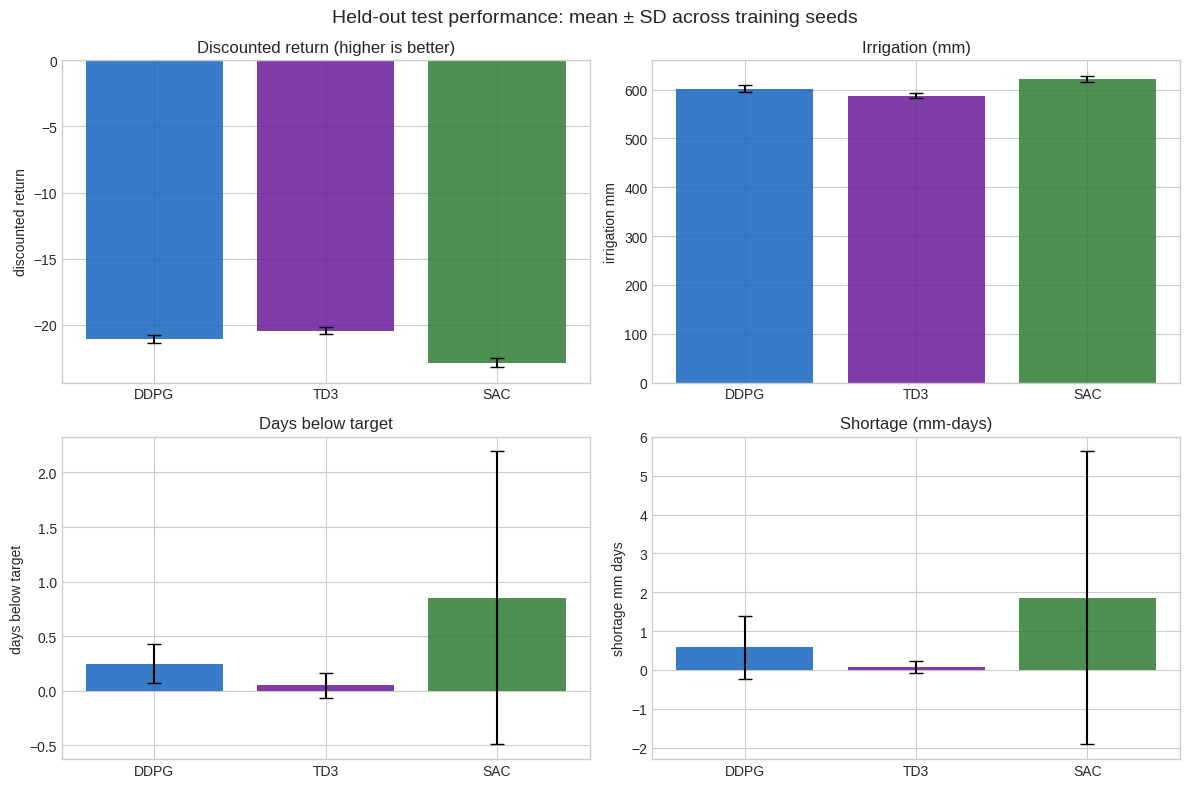

In [74]:
if not seed_level.empty:
    plot_metrics = ["discounted_return", "irrigation_mm", "days_below_target", "shortage_mm_days"]
    titles = ["Discounted return (higher is better)", "Irrigation (mm)", "Days below target", "Shortage (mm-days)"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, metric, title in zip(axes.flat, plot_metrics, titles):
        order = [agent for agent in AGENTS if agent in set(seed_level["agent"])]
        means = [seed_level.loc[seed_level["agent"].eq(agent), metric].mean() for agent in order]
        stds = [seed_level.loc[seed_level["agent"].eq(agent), metric].std(ddof=1) for agent in order]
        ax.bar([AGENT_LABELS[a] for a in order], means, yerr=stds, capsize=5, color=[AGENT_COLOURS[a] for a in order], alpha=0.85)
        ax.set_title(title)
        ax.set_ylabel(metric.replace("_", " "))
    fig.suptitle("Held-out test performance: mean ± SD across training seeds", fontsize=14)
    fig.tight_layout()
    fig.savefig(COMPARISON_DIR / "final_test_comparison.png", dpi=180, bbox_inches="tight")
    plt.show()


## 5. Generalisation across unseen climate years

This plot checks whether an algorithm's average result is driven by one unusually easy or difficult held-out season. Shading is the standard deviation across training seeds for each year.


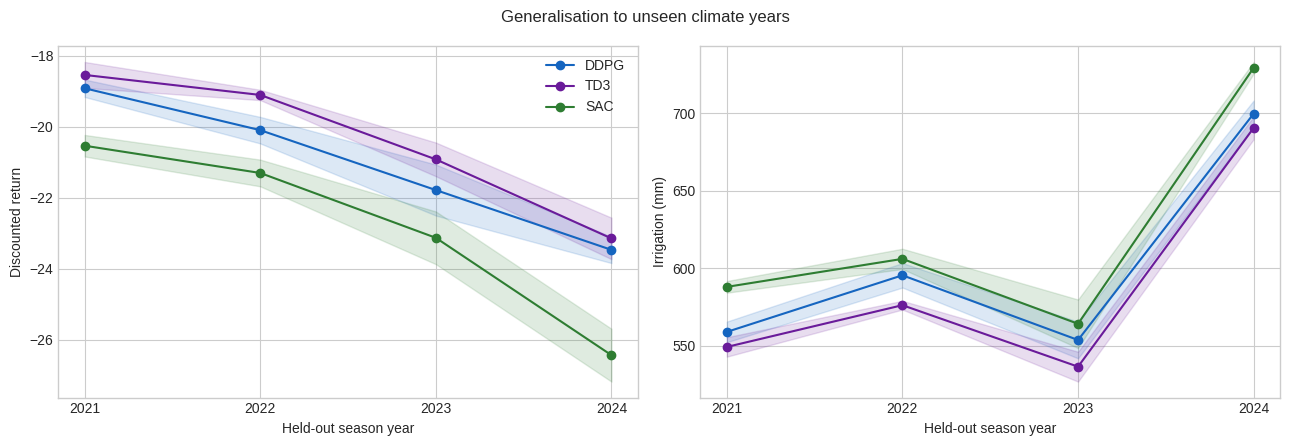

In [75]:
if not test_all.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for agent in AGENTS:
        subset = test_all.loc[test_all["agent"].eq(agent)]
        if subset.empty:
            continue
        by_year = subset.groupby("season_year").agg(
            return_mean=("discounted_return", "mean"), return_sd=("discounted_return", "std"),
            irrigation_mean=("irrigation_mm", "mean"), irrigation_sd=("irrigation_mm", "std"),
        ).reset_index()
        x = by_year["season_year"].to_numpy()
        for ax, mean_col, sd_col, ylabel in [
            (axes[0], "return_mean", "return_sd", "Discounted return"),
            (axes[1], "irrigation_mean", "irrigation_sd", "Irrigation (mm)"),
        ]:
            mean = by_year[mean_col].to_numpy()
            sd = by_year[sd_col].fillna(0).to_numpy()
            ax.plot(x, mean, marker="o", label=AGENT_LABELS[agent], color=AGENT_COLOURS[agent])
            ax.fill_between(x, mean - sd, mean + sd, alpha=0.15, color=AGENT_COLOURS[agent])
            ax.set_xlabel("Held-out season year")
            ax.set_ylabel(ylabel)
            ax.set_xticks(sorted(test_all["season_year"].dropna().unique().astype(int)))
    axes[0].legend()
    fig.suptitle("Generalisation to unseen climate years")
    fig.tight_layout()
    fig.savefig(COMPARISON_DIR / "test_year_generalisation.png", dpi=180, bbox_inches="tight")
    plt.show()


## 6. Convergence and training stability

Validation returns are averaged across validation seasons within each seed, then summarised across seeds at each evaluation step. Curves are descriptive: identical evaluation schedules are required before claiming one algorithm converges faster.


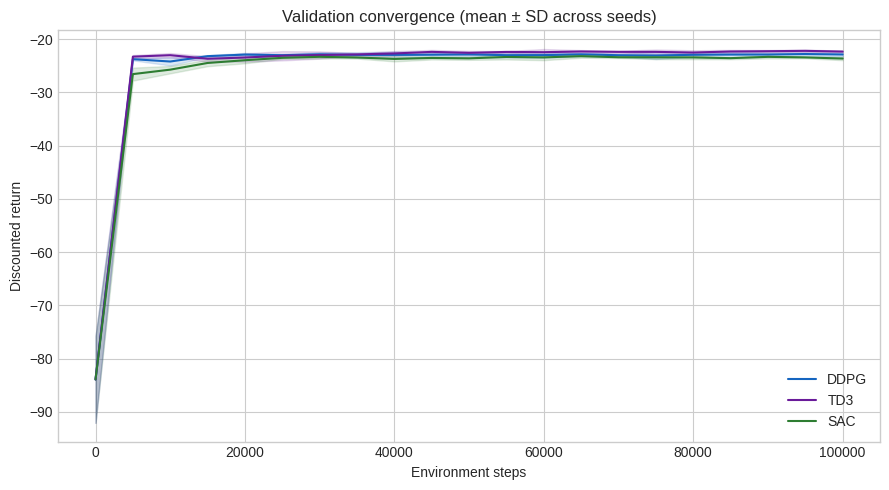

In [76]:
learning_frames = []
for agent in AGENTS:
    frame = results[agent]["learning"].copy()
    needed = {"seed", "training_steps", "discounted_return"}
    if frame.empty or not needed.issubset(frame.columns):
        continue
    if "status" in frame.columns:
        frame = frame.loc[frame["status"].eq("ok")]
    if "split" in frame.columns:
        frame = frame.loc[frame["split"].eq("validation")]
    frame["agent"] = agent
    learning_frames.append(frame)

if not learning_frames:
    print("No learning-curve files are available.")
else:
    learning_all = pd.concat(learning_frames, ignore_index=True)
    learning_seed = learning_all.groupby(["agent", "seed", "training_steps"], as_index=False)["discounted_return"].mean()
    learning_summary = learning_seed.groupby(["agent", "training_steps"])["discounted_return"].agg(["mean", "std", "count"]).reset_index()
    fig, ax = plt.subplots(figsize=(9, 5))
    for agent in AGENTS:
        curve = learning_summary.loc[learning_summary["agent"].eq(agent)].sort_values("training_steps")
        if curve.empty:
            continue
        x, mean = curve["training_steps"].to_numpy(), curve["mean"].to_numpy()
        sd = curve["std"].fillna(0).to_numpy()
        ax.plot(x, mean, label=AGENT_LABELS[agent], color=AGENT_COLOURS[agent])
        ax.fill_between(x, mean - sd, mean + sd, alpha=0.15, color=AGENT_COLOURS[agent])
    ax.set(title="Validation convergence (mean ± SD across seeds)", xlabel="Environment steps", ylabel="Discounted return")
    ax.legend()
    fig.tight_layout()
    fig.savefig(COMPARISON_DIR / "convergence_comparison.png", dpi=180, bbox_inches="tight")
    learning_summary.to_csv(COMPARISON_DIR / "convergence_summary.csv", index=False)
    plt.show()


## 7. Robustness comparison

Robustness scenarios are compared using `nominal_rescored_return` when available. This keeps the scoring rule fixed when the simulator is perturbed.


,agent,scenario,mean,std,count
0,ddpg,capacity_0.8,-33.902063,0.351068,5
1,ddpg,capacity_1.2,-30.800607,0.482216,5
2,ddpg,efficiency_0.75,-35.794204,0.461467,5
3,ddpg,efficiency_0.95,-29.268932,0.498688,5
4,ddpg,kc_0.9,-27.892729,0.400572,5
5,ddpg,kc_1.1,-36.818683,0.835511,5
6,ddpg,planting_minus_14d,-34.412139,0.481382,5
7,ddpg,planting_plus_14d,-30.323256,0.530408,5
8,ddpg,root_zone_0.6m,-35.873260,0.469035,5
9,sac,capacity_0.8,-35.761783,0.599081,5


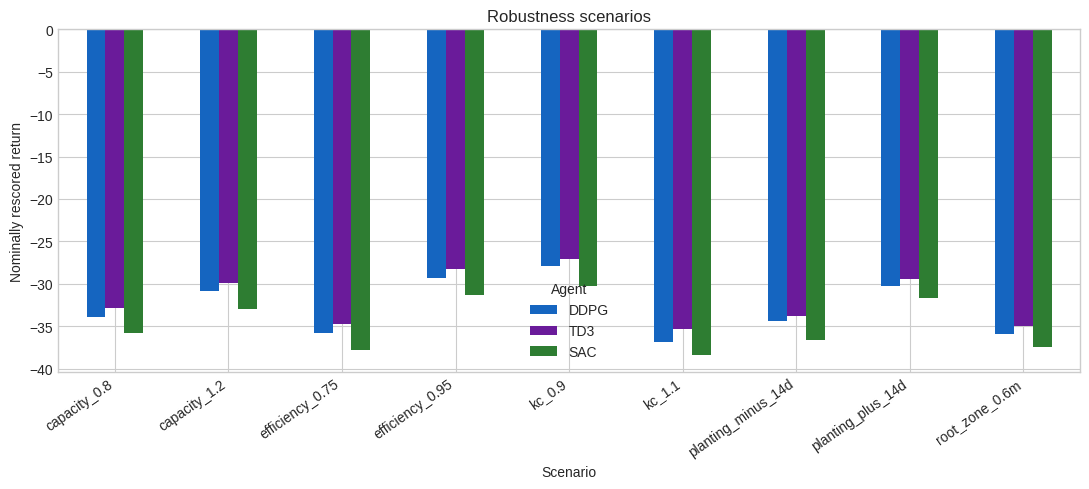

In [77]:
robust_frames = []
for agent in AGENTS:
    frame = results[agent]["robustness"].copy()
    if frame.empty or "scenario" not in frame.columns:
        continue
    metric = "nominal_rescored_return" if "nominal_rescored_return" in frame.columns else "discounted_return"
    if metric not in frame.columns:
        continue
    if "status" in frame.columns:
        frame = frame.loc[frame["status"].eq("ok")]
    frame["agent"] = agent
    frame["comparison_return"] = pd.to_numeric(frame[metric], errors="coerce")
    robust_frames.append(frame)

if not robust_frames:
    print("No robustness results are available.")
else:
    robustness_all = pd.concat(robust_frames, ignore_index=True)
    robustness_seed = robustness_all.groupby(["agent", "seed", "scenario"], as_index=False)["comparison_return"].mean()
    robustness_summary = robustness_seed.groupby(["agent", "scenario"])["comparison_return"].agg(["mean", "std", "count"]).reset_index()
    display(robustness_summary)
    pivot = robustness_summary.pivot(index="scenario", columns="agent", values="mean")
    pivot = pivot.reindex(columns=[a for a in AGENTS if a in pivot.columns])
    ax = pivot.rename(columns=AGENT_LABELS).plot(kind="bar", figsize=(11, 5), color=[AGENT_COLOURS[a] for a in pivot.columns])
    ax.set(title="Robustness scenarios", xlabel="Scenario", ylabel="Nominally rescored return")
    ax.legend(title="Agent")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(COMPARISON_DIR / "robustness_comparison.png", dpi=180, bbox_inches="tight")
    robustness_summary.to_csv(COMPARISON_DIR / "robustness_summary.csv", index=False)
    plt.show()


## 8. Reward-sensitivity analysis

These experiments use shorter sensitivity-training runs, so they show whether conclusions change with reward weighting; they do not replace the 100,000-step final comparison.


In [78]:
sensitivity_frames = []
for agent in AGENTS:
    frame = results[agent]["sensitivity"].copy()
    if frame.empty:
        continue
    if "scenario" not in frame.columns and "shortage_weight" in frame.columns:
        frame["scenario"] = "shortage_weight_" + frame["shortage_weight"].astype(str).str.replace(".0", "", regex=False)
    if "scenario" not in frame.columns:
        continue
    if "status" in frame.columns:
        frame = frame.loc[frame["status"].eq("ok")]
    frame["agent"] = agent
    sensitivity_frames.append(frame)

if not sensitivity_frames:
    print("No reward-sensitivity results are available.")
else:
    sensitivity_all = pd.concat(sensitivity_frames, ignore_index=True)
    sensitivity_seed = sensitivity_all.groupby(["agent", "seed", "scenario"], as_index=False)[["irrigation_mm", "days_below_target", "shortage_mm_days"]].mean()
    sensitivity_summary = sensitivity_seed.groupby(["agent", "scenario"])[["irrigation_mm", "days_below_target", "shortage_mm_days"]].agg(["mean", "std"])
    display(sensitivity_summary)
    sensitivity_summary.to_csv(COMPARISON_DIR / "reward_sensitivity_summary.csv")


irrigation_mm            days_below_target           shortage_mm_days           
                                  mean        std              mean       std             mean        std
agent scenario                                                                                           
ddpg  shortage_weight_20    669.757584  17.848974             0.125  0.176777         0.016404   0.023199
      shortage_weight_5     645.437497   2.127943             0.625  0.176777         0.266963   0.251620
sac   shortage_weight_20    676.110336  16.522997             0.000  0.000000         0.000000   0.000000
      shortage_weight_5     643.164028  19.323745             7.875  9.015611        28.393533  33.710754
td3   shortage_weight_20    655.769382   5.274393             0.000  0.000000         0.000000   0.000000
      shortage_weight_5     640.440576  10.194116             0.125  0.176777         0.113926   0.161116

## 9. Paired uncertainty between algorithms

For each pair, test years are averaged within each common seed. A fixed-seed non-parametric bootstrap then resamples the common training seeds. With only five seeds, the interval is descriptive and should be reported alongside the raw seed results, not as strong evidence of statistical significance.


In [79]:
def paired_seed_bootstrap(seed_table, agent_a, agent_b, metric, replicates=BOOTSTRAP_REPLICATES):
    pivot = seed_table.pivot(index="seed", columns="agent", values=metric).dropna(subset=[agent_a, agent_b])
    if pivot.empty:
        return None
    differences = (pivot[agent_a] - pivot[agent_b]).to_numpy()
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    boot = rng.choice(differences, size=(replicates, len(differences)), replace=True).mean(axis=1)
    low, high = np.quantile(boot, [0.025, 0.975])
    return {
        "comparison": f"{AGENT_LABELS[agent_a]} - {AGENT_LABELS[agent_b]}",
        "metric": metric, "common_seeds": len(differences),
        "mean_difference": differences.mean(), "ci_2.5%": low, "ci_97.5%": high,
    }

pairwise_rows = []
if not seed_level.empty:
    available = [agent for agent in AGENTS if agent in set(seed_level["agent"])]
    for i, agent_a in enumerate(available):
        for agent_b in available[i + 1:]:
            for metric in ["discounted_return", "irrigation_mm", "shortage_mm_days"]:
                row = paired_seed_bootstrap(seed_level, agent_a, agent_b, metric)
                if row:
                    pairwise_rows.append(row)
pairwise = pd.DataFrame(pairwise_rows)
if pairwise.empty:
    print("At least two agents with common final seeds are required.")
else:
    display(pairwise.round(3))
    pairwise.to_csv(COMPARISON_DIR / "paired_seed_bootstrap.csv", index=False)


,comparison,metric,common_seeds,mean_difference,ci_2.5%,ci_97.5%
0,DDPG - TD3,discounted_return,5,-0.638,-1.101,-0.176
1,DDPG - TD3,irrigation_mm,5,13.860,5.837,23.804
2,DDPG - TD3,shortage_mm_days,5,0.515,0.093,1.080
3,DDPG - SAC,discounted_return,5,1.783,1.314,2.233
4,DDPG - SAC,irrigation_mm,5,-19.940,-29.031,-10.849
5,DDPG - SAC,shortage_mm_days,5,-1.267,-3.991,0.245
6,TD3 - SAC,discounted_return,5,2.421,2.185,2.618
7,TD3 - SAC,irrigation_mm,5,-33.800,-38.732,-28.347
8,TD3 - SAC,shortage_mm_days,5,-1.782,-5.025,-0.090


## 10. Automatically generated findings and limitations


In [80]:
available_agents = [] if seed_level.empty else [agent for agent in AGENTS if agent in set(seed_level["agent"])]
findings = {
    "available_agents": [AGENT_LABELS[a] for a in available_agents],
    "missing_agents": [AGENT_LABELS[a] for a in AGENTS if a not in available_agents],
    "comparison_unit": "training-seed mean across held-out test seasons",
    "fixed_seeds": sorted(EXPECTED_SEEDS),
    "fixed_test_years": sorted(EXPECTED_TEST_YEARS),
    "fixed_training_steps": EXPECTED_TRAINING_STEPS,
    "limitations": [
        "Only five independent training seeds are used, so uncertainty estimates are imprecise.",
        "Performance is based on a simulated daily soil-water balance rather than a physical field trial.",
        "Convergence comparisons require identical evaluation intervals and validation years.",
        "Reward-sensitivity runs use a shorter budget and should not be ranked against final runs.",
    ],
}

if not seed_level.empty:
    return_means = seed_level.groupby("agent")["discounted_return"].mean()
    irrigation_means = seed_level.groupby("agent")["irrigation_mm"].mean()
    findings["highest_mean_return"] = AGENT_LABELS[return_means.idxmax()]
    findings["lowest_mean_irrigation"] = AGENT_LABELS[irrigation_means.idxmin()]

with open(COMPARISON_DIR / "comparison_findings.json", "w", encoding="utf-8") as handle:
    json.dump(findings, handle, indent=2)

print(json.dumps(findings, indent=2))
print("\nSaved comparison tables and figures to:", COMPARISON_DIR)


{
  "available_agents": [
    "DDPG",
    "TD3",
    "SAC"
  ],
  "missing_agents": [],
  "comparison_unit": "training-seed mean across held-out test seasons",
  "fixed_seeds": [
    11,
    22,
    33,
    44,
    55
  ],
  "fixed_test_years": [
    2021,
    2022,
    2023,
    2024
  ],
  "fixed_training_steps": 100000,
  "limitations": [
    "Only five independent training seeds are used, so uncertainty estimates are imprecise.",
    "Performance is based on a simulated daily soil-water balance rather than a physical field trial.",
    "Convergence comparisons require identical evaluation intervals and validation years.",
    "Reward-sensitivity runs use a shorter budget and should not be ranked against final runs."
  ],
  "highest_mean_return": "TD3",
  "lowest_mean_irrigation": "TD3"
}

Saved comparison tables and figures to: /content/comp6008-smart-irrigation-rl/outputs/comparison


### Independent preservation check of the 2021–2024 held-out results
This code re-reads the existing test CSVs; it does not use notebook-embedded numbers as data and does not modify the original files. Assertions check all expected seeds, years, 100,000-step training budget and the published mean/SD/irrigation values.


In [81]:
TEST_CSVS = {
    'DDPG': ROOT / 'outputs/ddpg/final/ddpg_test_results.csv',
    'TD3': ROOT / 'outputs/td3/final/td3_test_results.csv',
    'SAC': ROOT / 'outputs/sac/final/sac_final_test_all_seeds.csv',
}
EXPECTED_METRICS = {
    'DDPG': (-21.06422358818171, 0.3159817669741371, 601.8677581856318),
    'TD3': (-20.425993278129006, 0.2954715668002405, 588.007453918166),
    'SAC': (-22.846901562084575, 0.3594827901298183, 621.8078419241356),
}
verified=[]
for name,path in TEST_CSVS.items():
    table=pd.read_csv(path)
    assert len(table)==20, (name,'expected 5 training seeds x 4 test years')
    assert set(table['seed'])=={11,22,33,44,55},name
    assert set(table['season_year'])=={2021,2022,2023,2024},name
    assert set(table['training_steps'])=={100_000},name
    assert set(table['split'])=={'test'},name
    assert table['status'].eq('ok').all(),name
    seed_means=table.groupby('seed')['discounted_return'].mean()
    values=(float(seed_means.mean()),float(seed_means.std(ddof=1)),float(table['irrigation_mm'].mean()))
    np.testing.assert_allclose(values,EXPECTED_METRICS[name],rtol=0,atol=1e-4,
                               err_msg=f'{name} differs from the saved experiment summary')
    verified.append({'agent':name,'mean_return':values[0],'seed_sd':values[1],
                     'irrigation_mm':values[2]})
display(pd.DataFrame(verified))
print('PASS: All 60 held-out seed-season records agree with the saved group results.')


,agent,mean_return,seed_sd,irrigation_mm
0,DDPG,-21.064224,0.315982,601.867758
1,TD3,-20.425993,0.295472,588.007454
2,SAC,-22.846902,0.359483,621.807842


PASS: All 60 held-out seed-season records agree with the saved group results.


## G. Synchronized 2017 validation replay (saved seed-11 checkpoint policies)
This section reproduces the replay behaviour from `05_farm_replay.ipynb`, but uses the agent definitions already in this notebook; it does not extract Python code from other notebooks. It uses identical 2017 weather and starting storage for the threshold baseline, DDPG, TD3 and SAC. The 2017 **validation** replay must not be cited as held-out test performance.

Default: confirm the saved replay results. MP4 export is disabled until explicitly requested.


In [82]:
from IPython.display import Video
from matplotlib.animation import FuncAnimation, FFMpegWriter

# Keep the original replay media untouched; any re-export has a separate destination.
ROOT = PROJECT_ROOT
OUT = ROOT / "outputs" / "consolidated_replay"
YEAR, SEED, FPS = 2017, 11, 8
RUN_REPLAY_CHECK = True
GENERATE_NEW_MP4 = False


def policy_from_saved_actor(name, path):
    """Exact deterministic test-time policy using the final seed-11 actor weights."""
    checkpoint = torch.load(path, map_location='cpu', weights_only=False)
    if name == 'SAC':
        actor = SACActor(18, 1).cpu()
    else:
        actor = DeterministicActor(18, 1).cpu()
    actor.load_state_dict(checkpoint['actor'], strict=True)
    actor.eval()

    def select_action(observation):
        with torch.no_grad():
            output = actor(torch.as_tensor(observation, dtype=torch.float32).reshape(1, -1))
            if isinstance(output, tuple):
                output = torch.tanh(output[0])  # SAC evaluation = tanh(Gaussian mean)
            return output.cpu().numpy().ravel().astype(np.float32)
    return select_action

CHECKPOINTS = {
    'DDPG': ROOT / 'outputs/ddpg/final/ddpg_seed11.pt',
    'TD3': ROOT / 'outputs/td3/final/td3_seed11.pt',
    'SAC': ROOT / 'outputs/sac/final/sac_final_seed11.pt',
}

shared = {'KyabramIrrigationEnv': KyabramIrrigationEnv, 'SHARED_TRAINING': SHARED_TRAINING}
POLICIES = None
if RUN_REPLAY_CHECK:
    for name,path in CHECKPOINTS.items():
        if not path.exists(): raise FileNotFoundError(f'Missing original checkpoint: {path}')
    POLICIES = {name: policy_from_saved_actor(name, path) for name,path in CHECKPOINTS.items()}
    POLICIES['Threshold'] = threshold_policy


In [83]:
if RUN_REPLAY_CHECK:
    def trace(name, policy):
        env = KyabramIrrigationEnv(split='validation')
        obs,_ = env.reset(options={'season_year': YEAR})
        rows=[]; discounted=0.0
        for day in range(150):
            action = np.asarray(policy(obs),dtype=np.float32).reshape(1)
            obs,reward,terminated,truncated,info = env.step(action)
            discounted += SHARED_TRAINING['gamma']**day*reward
            rows.append({'agent':name,'day':day+1,'date':info['decision_date'],
                         'soil_mm':info['storage_after_mm'], 'minimum_mm':info['minimum_storage_mm'],
                         'irrigation_mm':info['irrigation_mm'],'rain_mm':info['rain_mm'],
                         'drainage_mm':info['drainage_mm'],'reward':reward})
        assert terminated and not truncated
        df=pd.DataFrame(rows)
        df['cumulative_irrigation_mm']=df['irrigation_mm'].cumsum()
        return df,{'agent':name,'year':YEAR,'seed':SEED if name!='Threshold' else None,
                   'discounted_return':discounted,'irrigation_mm':df['irrigation_mm'].sum(),
                   'days_below_target':int((df['soil_mm']<df['minimum_mm']).sum())}
    OUT.mkdir(parents=True,exist_ok=True)
    TRACES=[]; METRICS=[]
    for name,policy in POLICIES.items():
        df,metrics=trace(name,policy);TRACES.append(df);METRICS.append(metrics)
    replay=pd.concat(TRACES,ignore_index=True)
    replay.to_csv(OUT/'farm_replay_2017_daily.csv',index=False)
    pd.DataFrame(METRICS).to_csv(OUT/'farm_replay_2017_summary.csv',index=False)
    display(pd.DataFrame(METRICS))


,agent,year,seed,discounted_return,irrigation_mm,days_below_target
0,DDPG,2017,11.0,-23.620962,631.470098,0
1,TD3,2017,11.0,-22.349228,617.850332,0
2,SAC,2017,11.0,-25.736415,653.728234,0
3,Threshold,2017,NaN,-26.848137,680.000000,5


In [84]:
if GENERATE_NEW_MP4 and RUN_REPLAY_CHECK:
    # Separate output path: never replace the original replay or evidence.
    COLORS={'DDPG':'#3C7BB6','TD3':'#E58A40','SAC':'#6E62B5','Threshold':'#73837C'}
    import matplotlib.animation as animation
    fig, axs=plt.subplots(2,2,figsize=(12.8,7.2),sharex=True,layout='constrained')
    fig.patch.set_facecolor('white')
    line_cache={}
    for ax,name in zip(axs.flat,POLICIES):
        ax.set_title(name,fontweight='bold',color=COLORS[name]);ax.set_xlim(1,150);ax.set_ylim(0,115)
        ax.set_xlabel('Day of maize season');ax.set_ylabel('Soil water (mm)');ax.grid(alpha=.15)
        soil,=ax.plot([],[],color=COLORS[name],lw=2.6,label='Soil water')
        lower,=ax.plot([],[],color='#CF5959',ls='--',lw=1.3,label='Minimum target')
        info_box=ax.text(.02,.02,'',transform=ax.transAxes,va='bottom',fontsize=9)
        if name=='DDPG':ax.legend(loc='upper right',fontsize=8)
        line_cache[name]=(soil,lower,info_box,replay[replay.agent==name].reset_index(drop=True))
    fig.suptitle('ONE SEASON · SAME WEATHER · FOUR IRRIGATION STRATEGIES',fontsize=15,fontweight='bold')
    def replay_frame(i):
        for name,(soil,lower,box,df) in line_cache.items():
            sub=df.iloc[:i+1];row=sub.iloc[-1]
            soil.set_data(sub.day,sub.soil_mm)
            lower.set_data(sub.day,sub.minimum_mm)
            box.set_text(f'Day {int(row.day):03} | Today: {row.irrigation_mm:.1f} mm | '
                         f'Cumulative: {row.cumulative_irrigation_mm:.0f} mm\n'
                         f'Drainage today: {row.drainage_mm:.1f} mm')
        return []
    anim=FuncAnimation(fig,replay_frame,frames=150,interval=250,blit=False)
    OUT.mkdir(parents=True,exist_ok=True)
    anim.save(str(OUT/'farm_replay_2017.mp4'),writer=FFMpegWriter(fps=4,bitrate=2500))
    replay_frame(149)
    fig.savefig(OUT/'farm_replay_2017_preview.png',dpi=140,bbox_inches='tight')
    plt.show()


In [85]:
# Compare with the checked-in replay record; original values must not change.
if RUN_REPLAY_CHECK:
    original = pd.read_csv(ROOT/'outputs/replay/farm_replay_2017_summary.csv').set_index('agent')
    actual = pd.DataFrame(METRICS).set_index('agent')
    for field,tol in [('discounted_return', 0.001), ('irrigation_mm', 0.001), ('days_below_target', 0)]:
        deviation = (actual[field] - original[field]).abs().max()
        if deviation > tol:
            raise AssertionError(f'{field} differed from saved replay by {deviation:.6g} (tolerance {tol})')
    print('PASS: All four 2017 replay controllers reproduce the saved results.')

from IPython.display import display
video_path = ROOT/'outputs/replay/farm_replay_2017.mp4'
if video_path.exists():
    print('Previously exported video:', video_path)
    # Display the saved MP4 without embedding it in the notebook JSON output by default.


PASS: All four 2017 replay controllers reproduce the saved results.
Previously exported video: /content/comp6008-smart-irrigation-rl/outputs/replay/farm_replay_2017.mp4


### Dependency Management

Running `pip freeze` in Google Colab captured 646 packages, including
preinstalled libraries unrelated to our project and platform-specific
dependencies that may not work in other environments.

Instead, we dynamically scanned the project notebooks for imported
libraries and extracted their installed versions from `pip freeze`.

This produced a concise, project-specific `requirements.txt` containing
only the six direct dependencies required by our code.

In [94]:

%cd /content/comp6008-smart-irrigation-rl

import ast
import json
import re
import subprocess
import sys
from pathlib import Path
from importlib import metadata

# 1. Scan all project notebooks for imports
imports = set()

for notebook in Path("notebooks").glob("*.ipynb"):
    data = json.loads(notebook.read_text(encoding="utf-8"))

    for cell in data["cells"]:
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])

        # Ignore Colab/Jupyter magic commands
        source = "\n".join(
            "pass" if line.lstrip().startswith(("!", "%"))
            else line
            for line in source.splitlines()
        )

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        for node in ast.walk(tree):
            if isinstance(node, ast.Import):
                imports.update(
                    name.name.split(".")[0]
                    for name in node.names
                )
            elif isinstance(node, ast.ImportFrom) and node.module:
                imports.add(node.module.split(".")[0])

# 2. Map imports to installed packages
package_map = metadata.packages_distributions()

def normalize(name):
    return re.sub(r"[-_.]+", "-", name).lower()

needed = {
    normalize(package)
    for module in imports
    if module not in sys.stdlib_module_names
    for package in package_map.get(module, [])
}

# 3. Get actual installed versions using pip freeze
frozen = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"],
    text=True
)

requirements = []

for line in frozen.splitlines():
    package = re.split(r"==|\s+@\s+", line, maxsplit=1)[0]
    package = normalize(package)

    if package not in needed:
        continue

    # Convert platform-specific wheel URLs to versions
    if " @ " in line:
        version = metadata.version(package).split("+")[0]
        line = f"{package}=={version}"

    requirements.append(line)

# 4. Save requirements.txt
requirements = sorted(set(requirements), key=str.lower)

output = Path("requirements.txt")
output.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

# 5. Display final requirements
print("Generated requirements.txt:\n")
print(output.read_text())
print(f"Total dependencies: {len(requirements)}")
print(f"Saved to: {output.resolve()}")


/content/comp6008-smart-irrigation-rl
Generated requirements.txt:

gymnasium==1.4.0
ipython==7.34.0
matplotlib==3.10.0
numpy==2.1.3
pandas==2.2.3
torch==2.11.0

Total dependencies: 6
Saved to: /content/comp6008-smart-irrigation-rl/requirements.txt
